# Module 3 · Lab 3.3 — Swarm Pattern: E-Commerce Order Lifecycle
## Peer-to-peer agent handoffs — no central supervisor

## Swarm Pattern: Peer-to-Peer Agent Handoffs (No Central Supervisor)

In this lab we build a **Swarm** of 6 autonomous agents that manage an e-commerce order lifecycle. Unlike the Supervisor pattern (Lab 3.1), there is **no central coordinator** -- each agent decides autonomously whether to handle the request or hand off to a peer.

| Step | What We Build | Key Concept |
|------|--------------|-------------|
| 1 | Domain tools (order, inventory, payment, shipping, returns, fraud, cancel, block) | Tool-per-capability |
| 2 | Handoff tools using `Command` + `ToolRuntime` | Peer-to-peer transfer |
| 3 | 6 specialist agents via `create_agent` | Autonomous agents |
| 4 | Swarm graph via `StateGraph` | Decentralized orchestration |
| 5 | Test cases across 7 lifecycle scenarios (happy path, return, fraud, OOS, unknown order, payment failure, alternate happy path) | End-to-end validation |

## Learning Objectives

1. Implement the **Swarm** agentic pattern with peer-to-peer agent handoffs
2. Create handoff tools that transfer control between agents using `Command` and `ToolRuntime`
3. Understand when to use **Swarm vs Supervisor** patterns and their trade-offs
4. Build a multi-agent system where agents **self-organize** without central control
5. Use structured `handoff_log` state (with an `operator.add` reducer) to trace handoff sequences
6. Learn why **topology** (tool availability) enforces workflow order more reliably than prompts alone

## Swarm vs Supervisor: What's Different?

| Aspect | Supervisor (Lab 3.1) | Swarm (Lab 3.3) |
|--------|-------------------|----------------|
| **Routing** | Central supervisor decides | Each agent decides autonomously |
| **Control** | Centralized | Decentralized |
| **Handoffs** | Supervisor -> Specialist -> Supervisor | Agent -> Agent -> Agent |
| **Context** | Supervisor maintains global context | Context travels with handoffs |
| **Best for** | Clear hierarchies, consistent routing | Organic workflows, exploration |
| **LangChain pattern** | Supervisor subagents | Handoffs (Command.PARENT) |

## How Swarm Handoffs Work

Each agent has **handoff tools** -- when it calls a handoff tool, it transfers control to the target agent via `Command(goto=..., graph=Command.PARENT)`. The full conversation history travels with the handoff so the receiving agent has full context.

```
                          Customer
                             |
                             v
                     +----------------+
                     |  Intake Agent  |  (entry point)
                     +----------------+
                     /     |      \      \
                    v      v       v       v
              +--------+ +-------+ +--------+ +--------+
              | Fraud  | |Invent.| |Returns | |Intake  |
              +--------+ +-------+ +--------+ +--------+
                 |  \       |          |
                 v   v      v          v
            +--------+ +--------+ +--------+
            |Payment | |Payment | |Intake  |
            +--------+ +--------+ +--------+
                 |
                 v
            +--------+
            |Shipping|  (terminal for successful orders)
            +--------+
```

Note that not every agent can reach every other agent. The graph topology is deliberately scoped: the Intake agent has no direct handoff to Payment or Shipping, so a happy-path order is forced through Inventory -> Payment -> Shipping. This is what makes workflow enforcement *structural* instead of just prompt-based.


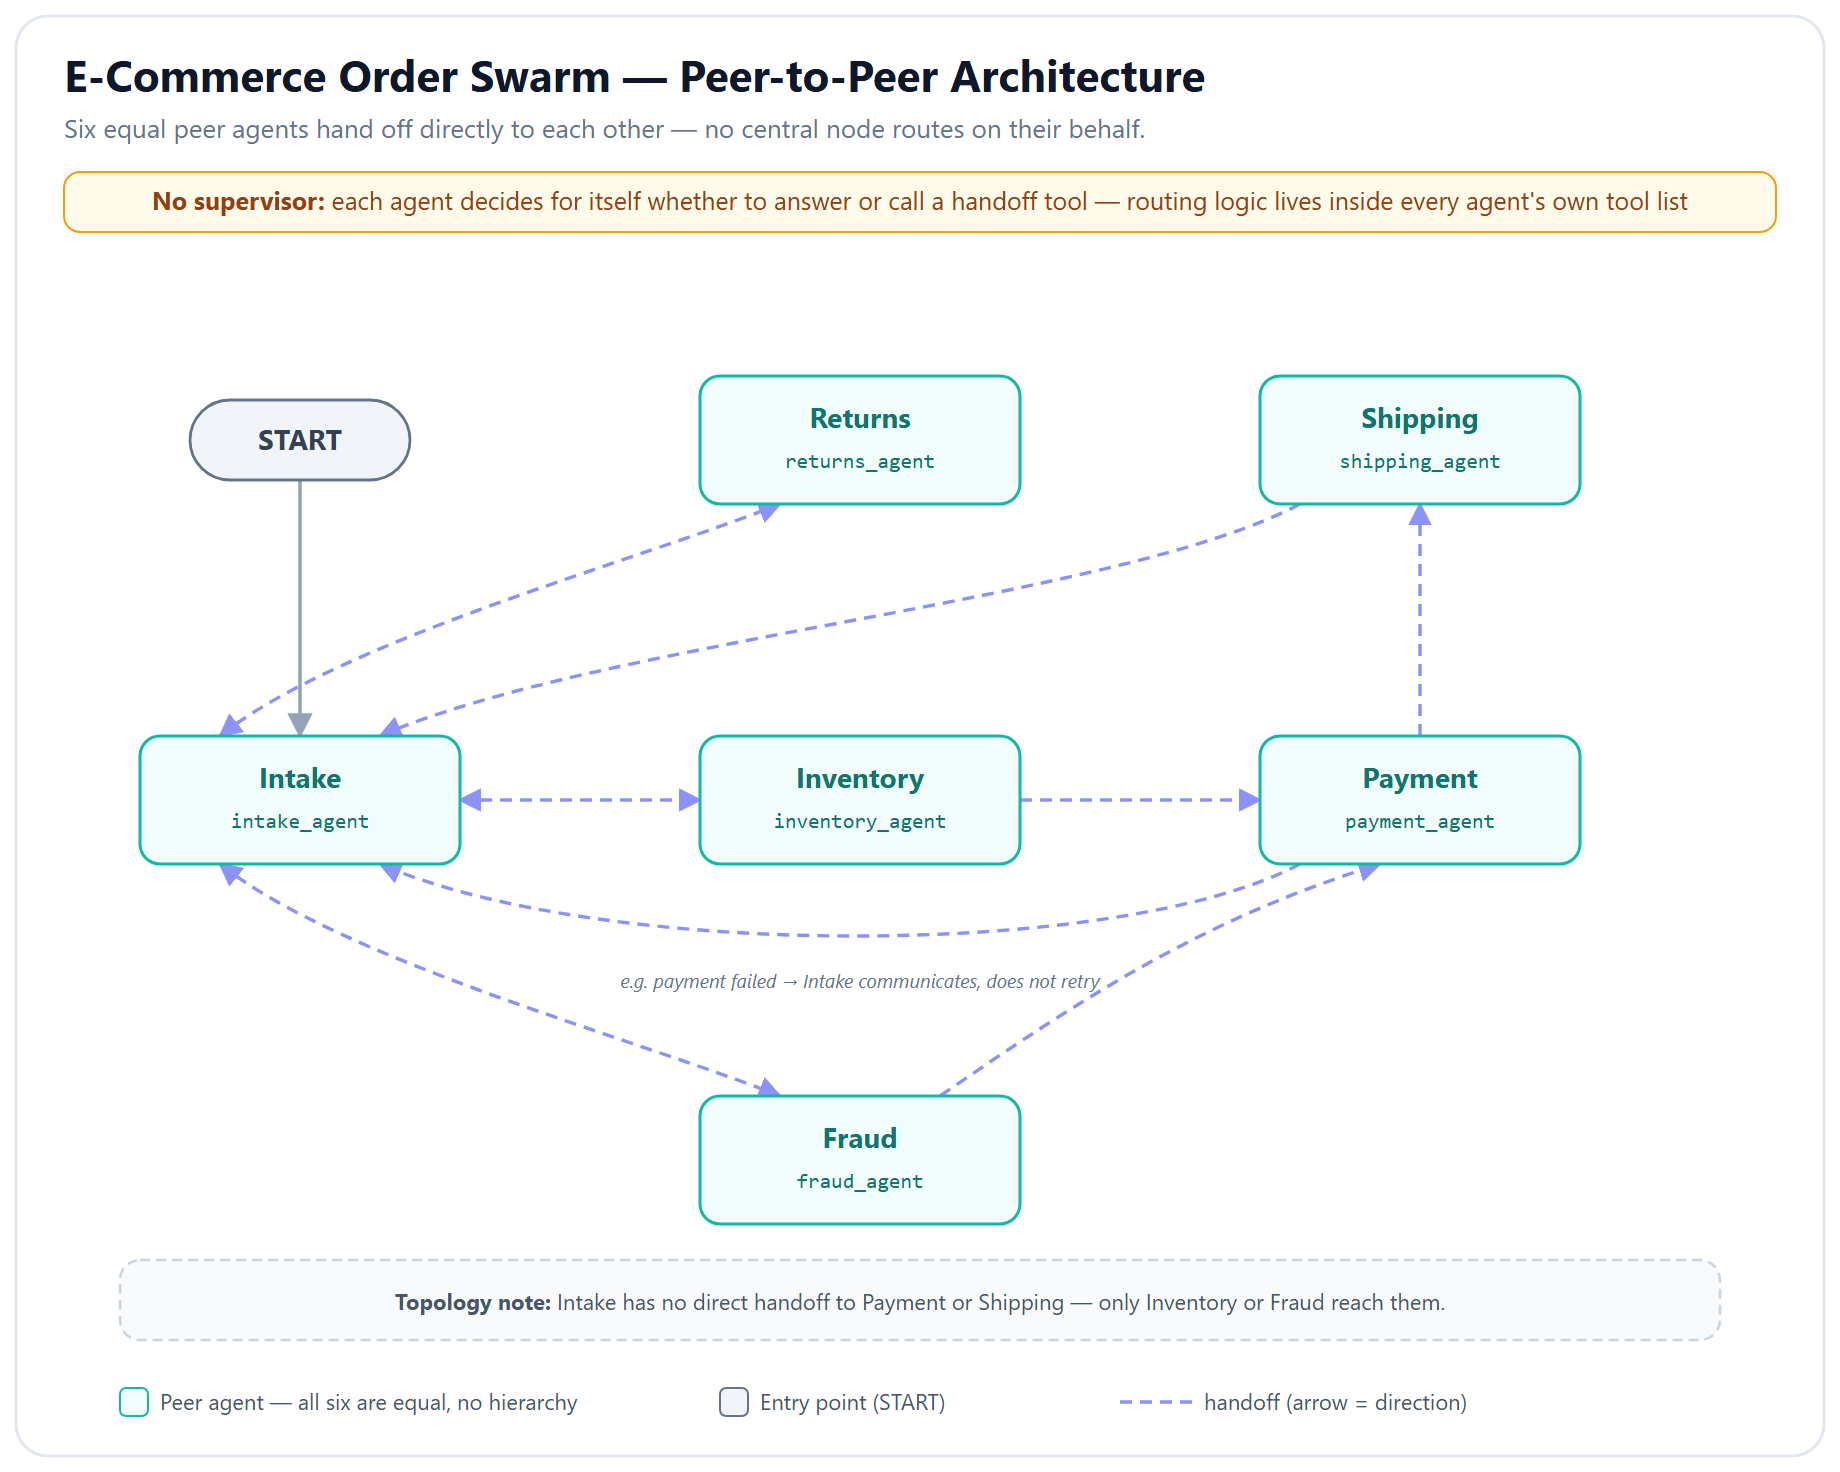

**Figure — E-commerce order swarm, peer-to-peer architecture.** Six equal peer agents hand off directly to each other over a deliberately scoped set of edges — Intake has no direct handoff to Payment or Shipping — with no central node ever deciding on their behalf.

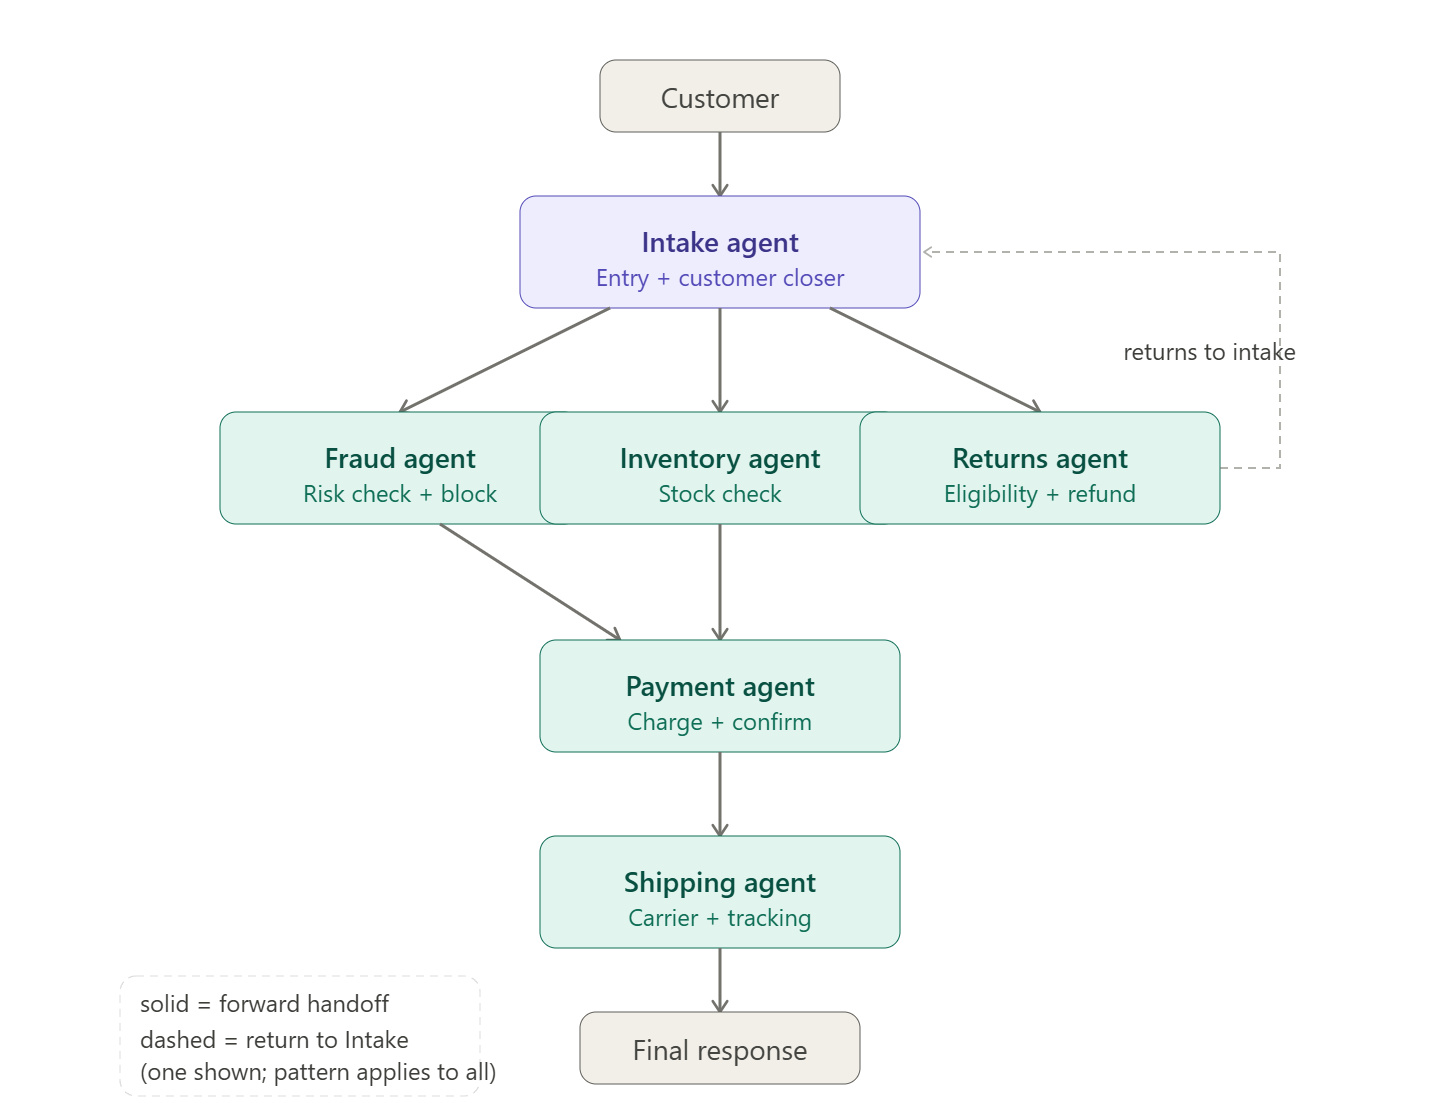

## 1. Environment Setup

In [ ]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-core langchain-openai langgraph langgraph-swarm pydantic python-dotenv

In [ ]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"🔑 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")

load_keys(["OPENAI_API_KEY"])

In [ ]:
# ============================================================
# All Imports
# ============================================================
from typing import Literal
from typing_extensions import NotRequired

from langchain.agents import AgentState, create_agent
from langchain.messages import AIMessage, ToolMessage
from langchain.tools import tool, ToolRuntime
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image, display
import random, datetime, hashlib

print("All imports successful")

## 2. Business Scenario: ShopSmart Order Lifecycle

An e-commerce order goes through multiple stages:

| Stage | Agent | Responsibility |
|-------|-------|---------------|
| 1. Order Intake | `intake_agent` | Receive customer requests, validate, route |
| 2. Inventory Check | `inventory_agent` | Verify stock availability across warehouses |
| 3. Payment Processing | `payment_agent` | Charge customer, handle payment failures |
| 4. Shipping | `shipping_agent` | Select carrier, generate tracking, schedule delivery |
| 5. Returns | `returns_agent` | Handle return requests, check eligibility, process refunds |
| 6. Fraud Detection | `fraud_agent` | Flag suspicious patterns, block fraudulent orders |

In a traditional system, these are handled by separate teams passing tickets around. In our **Swarm**, each stage is an autonomous agent that hands off to the next stage when its work is done -- with **no central supervisor** making routing decisions.

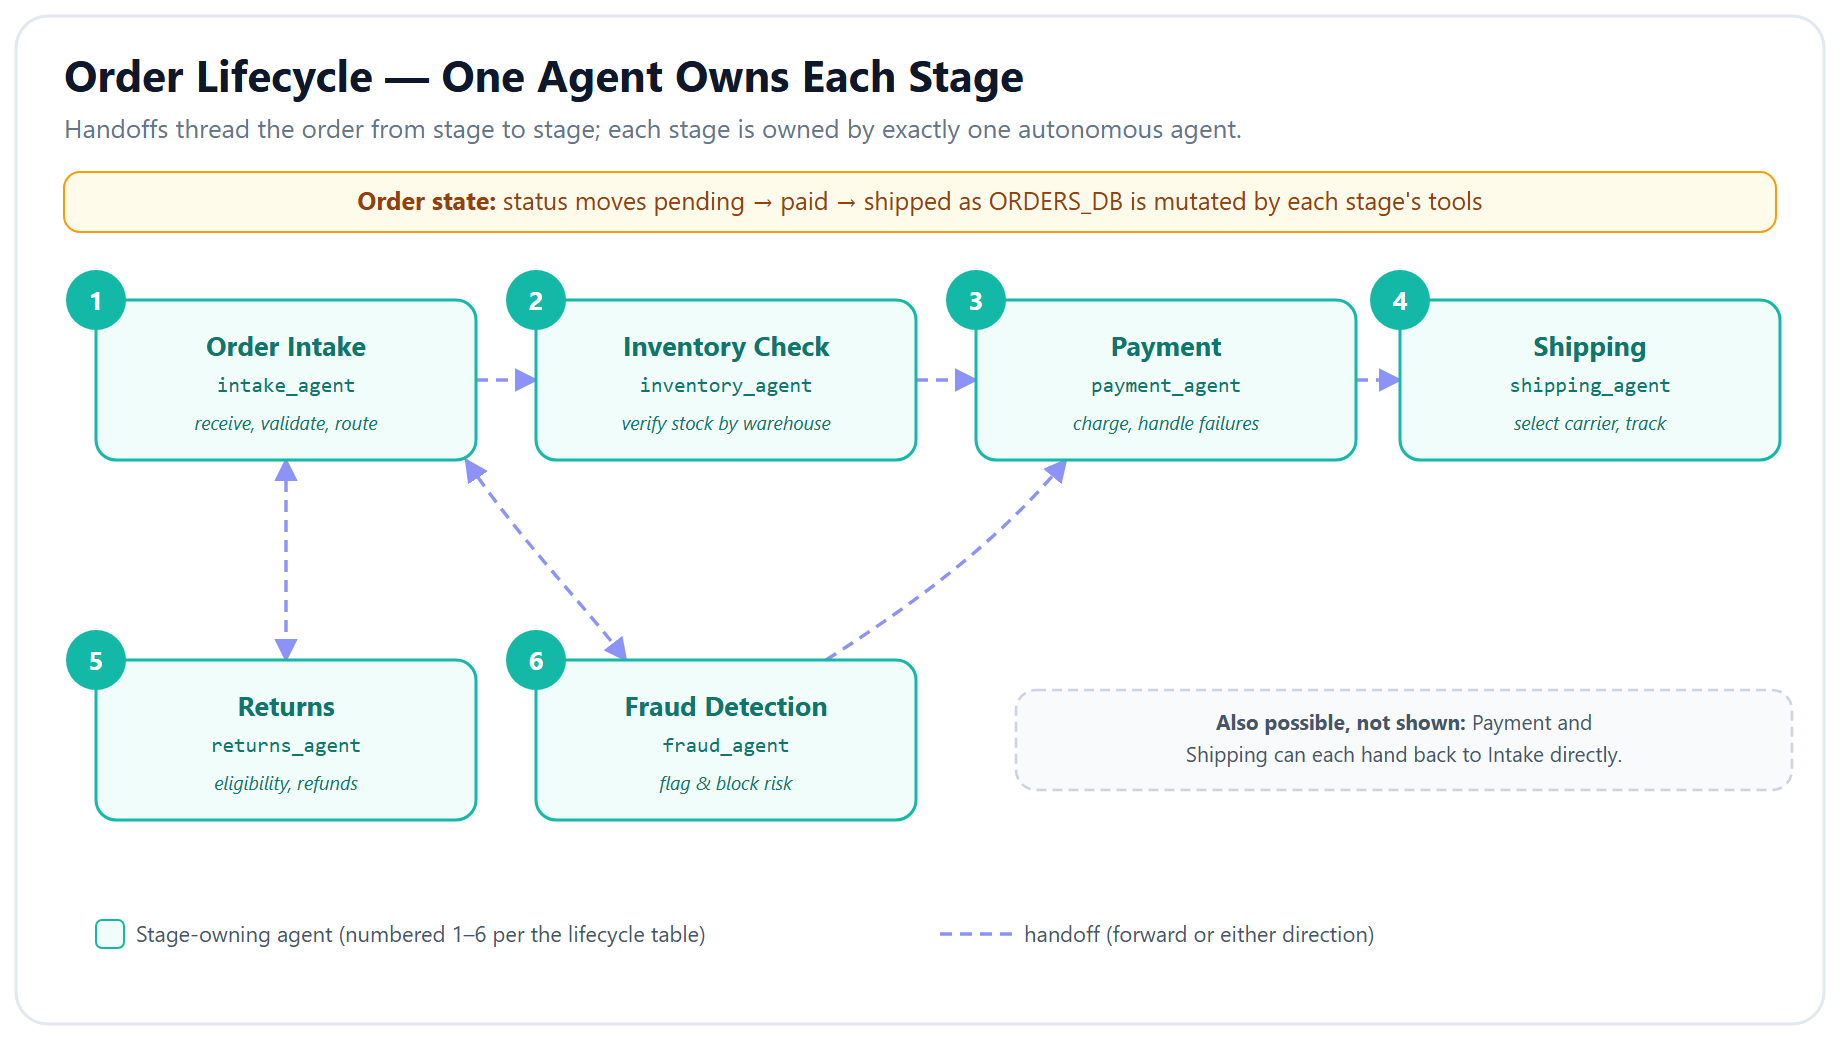

**Figure — Order lifecycle, one agent per stage.** `intake_agent → inventory_agent → payment_agent → shipping_agent` is the happy-path spine; `returns_agent` and `fraud_agent` branch off intake via the same handoff tools.

In [ ]:
# ============================================================
# Synthetic E-Commerce Data (all inline -- no external files)
# ============================================================

import copy

# --- Order Database (10 orders with various statuses) ---
ORDERS_DB = {
    "ORD-1001": {
        "customer": "Ananya Sharma", "email": "ananya@email.com",
        "items": [{"name": "Wireless Earbuds", "qty": 1, "price": 2499}],
        "total": 2499, "status": "pending", "payment_status": "pending",
        "address": "Bandra West, Mumbai, MH 400050",
        "order_date": "2026-04-06", "is_new_customer": False
    },
    "ORD-1002": {
        "customer": "Rahul Verma", "email": "rahul.v@email.com",
        "items": [{"name": "Running Shoes", "qty": 1, "price": 4999}, {"name": "Sports Watch", "qty": 1, "price": 8999}],
        "total": 13998, "status": "paid", "payment_status": "completed",
        "address": "Connaught Place, Delhi, DL 110001",
        "order_date": "2026-04-04", "is_new_customer": False
    },
    "ORD-1003": {
        "customer": "Priya Nair", "email": "priya.n@email.com",
        "items": [{"name": "Yoga Mat", "qty": 2, "price": 1299}],
        "total": 2598, "status": "shipped", "payment_status": "completed",
        "address": "Koramangala, Bengaluru, KA 560034",
        "order_date": "2026-03-20", "is_new_customer": False
    },
    "ORD-1004": {
        "customer": "Vikram Singh", "email": "vikram.s@email.com",
        "items": [{"name": "Laptop Stand", "qty": 1, "price": 1899}, {"name": "USB-C Hub", "qty": 1, "price": 2499}],
        "total": 4398, "status": "delivered", "payment_status": "completed",
        "address": "Banjara Hills, Hyderabad, TS 500034",
        "order_date": "2026-03-01", "is_new_customer": False
    },
    "ORD-1005": {
        "customer": "Meera Joshi", "email": "meera.j@email.com",
        "items": [{"name": "Silk Saree", "qty": 1, "price": 15999}],
        "total": 15999, "status": "pending", "payment_status": "pending",
        "address": "Salt Lake, Kolkata, WB 700091",
        "order_date": "2026-04-07", "is_new_customer": False
    },
    "ORD-1006": {
        "customer": "Arjun Reddy", "email": "arjun.r@email.com",
        "items": [{"name": "Gaming Mouse", "qty": 3, "price": 999}, {"name": "Mechanical Keyboard", "qty": 1, "price": 5499}],
        "total": 8496, "status": "pending", "payment_status": "pending",
        "address": "Anna Nagar, Chennai, TN 600040",
        "order_date": "2026-04-08", "is_new_customer": True
    },
    "ORD-1007": {
        "customer": "Sneha Patil", "email": "sneha.p@email.com",
        "items": [{"name": "Air Purifier", "qty": 1, "price": 12999}],
        "total": 12999, "status": "delivered", "payment_status": "completed",
        "address": "Aundh, Pune, MH 411007",
        "order_date": "2026-02-15", "is_new_customer": False
    },
    "ORD-1008": {
        "customer": "Karthik Iyer", "email": "karthik.i@email.com",
        "items": [{"name": "Bluetooth Speaker", "qty": 5, "price": 3999}],
        "total": 19995, "status": "pending", "payment_status": "pending",
        "address": "MG Road, Kochi, KL 682016",
        "order_date": "2026-04-08", "is_new_customer": True
    },
    "ORD-1009": {
        "customer": "Divya Gupta", "email": "divya.g@email.com",
        "items": [{"name": "Wireless Earbuds", "qty": 1, "price": 2499}],
        "total": 2499, "status": "paid", "payment_status": "completed",
        "address": "Civil Lines, Jaipur, RJ 302006",
        "order_date": "2026-04-05", "is_new_customer": False
    },
    "ORD-1010": {
        "customer": "Rohan Das", "email": "rohan.d@email.com",
        "items": [{"name": "Premium Headphones", "qty": 1, "price": 29999}],
        "total": 29999, "status": "pending", "payment_status": "pending",
        "address": "Gomti Nagar, Lucknow, UP 226010",
        "order_date": "2026-04-08", "is_new_customer": True
    },
}

# --- Inventory Database ---
INVENTORY_DB = {
    "Wireless Earbuds": {"stock": 150, "warehouse": "Mumbai", "restock_date": None},
    "Running Shoes": {"stock": 0, "warehouse": "Delhi", "restock_date": "2026-04-15"},   # OUT OF STOCK
    "Sports Watch": {"stock": 45, "warehouse": "Delhi", "restock_date": None},
    "Yoga Mat": {"stock": 200, "warehouse": "Bengaluru", "restock_date": None},
    "Laptop Stand": {"stock": 80, "warehouse": "Hyderabad", "restock_date": None},
    "USB-C Hub": {"stock": 120, "warehouse": "Hyderabad", "restock_date": None},
    "Silk Saree": {"stock": 25, "warehouse": "Kolkata", "restock_date": None},
    "Gaming Mouse": {"stock": 300, "warehouse": "Chennai", "restock_date": None},
    "Mechanical Keyboard": {"stock": 60, "warehouse": "Chennai", "restock_date": None},
    "Air Purifier": {"stock": 35, "warehouse": "Pune", "restock_date": None},
    "Bluetooth Speaker": {"stock": 90, "warehouse": "Kochi", "restock_date": None},
    "Premium Headphones": {"stock": 15, "warehouse": "Lucknow", "restock_date": None},
}

# --- Shipping Carriers ---
CARRIERS = {
    "BlueDart": {"rate_per_kg": 99, "est_days": 3, "tracking_prefix": "BD", "metro_only": False},
    "DTDC": {"rate_per_kg": 79, "est_days": 5, "tracking_prefix": "DT", "metro_only": False},
    "Delhivery": {"rate_per_kg": 129, "est_days": 2, "tracking_prefix": "DL", "metro_only": True},
    "Ekart": {"rate_per_kg": 69, "est_days": 4, "tracking_prefix": "EK", "metro_only": False},
}

# --- Fraud Detection Rules (non-overlapping by design) ---
FRAUD_RULES = {
    "high_value_new_customer": {"threshold": 15000, "risk": "high",
        "description": "New customer placing order above INR 15,000"},
    "bulk_quantity": {"threshold": 4, "risk": "medium",
        "description": "Single item quantity above 4 units"},
    "bulk_new_customer": {"threshold": 3, "risk": "high",
        "description": "New customer ordering more than 3 distinct items"},
}

# --- Return Policy ---
RETURN_POLICY = {
    "window_days": 30,
    "non_returnable": ["Silk Saree", "Yoga Mat"],
    "restocking_fee_pct": 5,
}

# --- Payment testing override ---
# Empty by default = normal 90% random success rate. Test cells can set
# PAYMENT_OVERRIDE["ORD-XXXX"] = "fail" (or "succeed") to force a deterministic
# outcome. This makes failure-path tests reliable instead of depending on RNG.
PAYMENT_OVERRIDE = {}

# --- Deep-copy snapshots for reset_demo_state() ---
_ORDERS_DB_INIT = copy.deepcopy(ORDERS_DB)
_INVENTORY_DB_INIT = copy.deepcopy(INVENTORY_DB)


def reset_demo_state():
    """Restore ORDERS_DB and INVENTORY_DB to their initial state.

    Tools mutate these dicts (process_payment sets status=paid, generate_tracking
    sets status=shipped, etc.), so re-running a test would get different behavior
    on the second pass. Calling this between tests makes each run reproducible
    and independent of the order in which tests were executed.
    """
    global ORDERS_DB, INVENTORY_DB, PAYMENT_OVERRIDE
    ORDERS_DB.clear()
    ORDERS_DB.update(copy.deepcopy(_ORDERS_DB_INIT))
    INVENTORY_DB.clear()
    INVENTORY_DB.update(copy.deepcopy(_INVENTORY_DB_INIT))
    PAYMENT_OVERRIDE.clear()


print(f"Data loaded: {len(ORDERS_DB)} orders, {len(INVENTORY_DB)} products, {len(CARRIERS)} carriers")
print(f"Fraud rules: {len(FRAUD_RULES)} | Return window: {RETURN_POLICY['window_days']} days")
print(f"reset_demo_state() available for reproducible test runs.")


## 3. Step 1 -- Define Domain Tools

Each agent needs **domain-specific tools** to perform its actual work (checking orders, processing payments, etc.). These are separate from the handoff tools we will create in Step 2.

| Tool | Used By | Purpose |
|------|---------|---------|
| `check_order` | Intake | Look up order details |
| `check_inventory` | Inventory | Verify stock levels |
| `process_payment` | Payment | Charge the customer |
| `select_carrier` | Shipping | Pick best carrier for destination |
| `generate_tracking` | Shipping | Create tracking number |
| `check_return_eligibility` | Returns | Verify return policy compliance |
| `process_refund` | Returns | Issue refund |
| `check_fraud_risk` | Fraud | Analyze order for suspicious patterns |
| `cancel_order` | Intake | Cancel an order (customer accepts cancellation) |
| `block_order` | Fraud | Block an order pending manual review (HIGH risk) |


In [ ]:
# ============================================================
# Domain-Specific Tools
# ============================================================

@tool
def check_order(order_id: str) -> str:
    """Look up order details by order ID. Returns order status, items, and customer info.

    Args:
        order_id: The order ID (e.g., ORD-1001)
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Order {order_id} not found in the system."

    items_str = ", ".join([f"{item['name']} x{item['qty']} @ INR {item['price']}" for item in order["items"]])
    return (
        f"Order {order_id}:\n"
        f"  Customer: {order['customer']}\n"
        f"  Items: {items_str}\n"
        f"  Total: INR {order['total']}\n"
        f"  Status: {order['status']}\n"
        f"  Payment: {order['payment_status']}\n"
        f"  Address: {order['address']}\n"
        f"  Order Date: {order['order_date']}\n"
        f"  New Customer: {order['is_new_customer']}"
    )


@tool
def check_inventory(product_name: str) -> str:
    """Check stock availability for a product. Returns stock count, warehouse location, and restock date if out of stock.

    Args:
        product_name: Exact product name (e.g., Wireless Earbuds)
    """
    item = INVENTORY_DB.get(product_name)
    if not item:
        return f"Product '{product_name}' not found in inventory database."

    if item["stock"] > 0:
        return f"PRODUCT: {product_name} | IN STOCK: {item['stock']} units | Warehouse: {item['warehouse']}"
    else:
        restock = item.get("restock_date", "Unknown")
        return f"PRODUCT: {product_name} | OUT OF STOCK | Warehouse: {item['warehouse']} | Expected restock: {restock}"


@tool
def process_payment(order_id: str) -> str:
    """Process payment for an order. Simulates payment gateway call. Returns success or failure.

    Args:
        order_id: The order ID to process payment for
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Payment failed: Order {order_id} not found."

    if order["payment_status"] == "completed":
        return f"Payment already completed for order {order_id}. No action needed."

    if order["status"] in ("cancelled", "blocked", "returned"):
        return f"Payment refused: Order {order_id} is {order['status']}. Cannot charge."

    # Honor test override (for deterministic testing), else fall back to 90% success rate
    override = PAYMENT_OVERRIDE.get(order_id)
    if override == "fail":
        success = False
    elif override == "succeed":
        success = True
    else:
        success = random.random() < 0.9

    if success:
        order["payment_status"] = "completed"
        order["status"] = "paid"
        return f"PAYMENT SUCCESS: Order {order_id} charged INR {order['total']} to customer {order['customer']}. Transaction ID: TXN-{hashlib.md5(order_id.encode()).hexdigest()[:8].upper()}"
    else:
        return f"PAYMENT FAILED: Order {order_id} -- insufficient funds or card declined. Customer: {order['customer']}. Please inform intake agent."


@tool
def select_carrier(order_id: str) -> str:
    """Select the best shipping carrier based on destination, speed, and cost.

    Args:
        order_id: The order ID to select a carrier for
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Cannot select carrier: Order {order_id} not found."

    address = order["address"]
    metro_cities = ["Mumbai", "Delhi", "Bengaluru", "Chennai", "Kolkata", "Hyderabad"]
    is_metro = any(city in address for city in metro_cities)

    best_carrier_name = None
    for carrier_name, carrier_details in CARRIERS.items():
        if carrier_details["metro_only"] and not is_metro:
            continue
        if (best_carrier_name is None
                or carrier_details["est_days"] < CARRIERS[best_carrier_name]["est_days"]):
            best_carrier_name = carrier_name

    selected_carrier = CARRIERS[best_carrier_name]
    return (
        f"CARRIER SELECTED: {best_carrier_name}\n"
        f"  Destination: {address}\n"
        f"  Estimated delivery: {selected_carrier['est_days']} business days\n"
        f"  Shipping cost: INR {selected_carrier['rate_per_kg']}\n"
        f"  Metro delivery: {'Yes' if is_metro else 'No'}"
    )


@tool
def generate_tracking(order_id: str, carrier: str) -> str:
    """Generate a tracking number for a shipment.

    Args:
        order_id: The order ID
        carrier: Carrier name (BlueDart, DTDC, Delhivery, Ekart)
    """
    carrier_info = CARRIERS.get(carrier)
    if not carrier_info:
        return f"Unknown carrier: {carrier}. Valid carriers: {', '.join(CARRIERS.keys())}"

    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Cannot generate tracking: Order {order_id} not found."

    # Idempotency guard: never double-ship
    if order["status"] == "shipped":
        return f"Order {order_id} is already shipped. Tracking already issued."
    if order["status"] != "paid":
        return f"Cannot ship order {order_id}: status is '{order['status']}', expected 'paid'."

    tracking_num = f"{carrier_info['tracking_prefix']}{hashlib.md5(order_id.encode()).hexdigest()[:10].upper()}"
    order["status"] = "shipped"
    return (
        f"TRACKING GENERATED:\n"
        f"  Order: {order_id}\n"
        f"  Carrier: {carrier}\n"
        f"  Tracking Number: {tracking_num}\n"
        f"  Customer: {order['customer']}\n"
        f"  Destination: {order['address']}\n"
        f"  Estimated delivery: {carrier_info['est_days']} business days"
    )


@tool
def check_return_eligibility(order_id: str) -> str:
    """Check if an order is eligible for return based on the return policy (30-day window, non-returnable items).

    Args:
        order_id: The order ID to check
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Order {order_id} not found."

    if order["status"] not in ["delivered", "shipped"]:
        return f"Order {order_id} is not yet delivered (status: {order['status']}). Cannot process return."

    order_date = datetime.datetime.strptime(order["order_date"], "%Y-%m-%d").date()
    today = datetime.date(2026, 4, 8)
    days_since = (today - order_date).days

    if days_since > RETURN_POLICY["window_days"]:
        return (
            f"RETURN DENIED: Order {order_id} is {days_since} days old. "
            f"Return window is {RETURN_POLICY['window_days']} days. "
            f"This denial is FINAL --- there is no goodwill-exception workflow available."
        )

    non_returnable_items = [item["name"] for item in order["items"]
                            if item["name"] in RETURN_POLICY["non_returnable"]]
    if non_returnable_items:
        return (
            f"RETURN DENIED: Items not eligible for return: {', '.join(non_returnable_items)}. "
            f"Policy non-returnable list: {RETURN_POLICY['non_returnable']}. "
            f"This denial is FINAL."
        )

    restocking_fee = int(order["total"] * RETURN_POLICY["restocking_fee_pct"] / 100)
    refund_amount = order["total"] - restocking_fee
    return (
        f"RETURN ELIGIBLE:\n"
        f"  Order: {order_id} | Customer: {order['customer']}\n"
        f"  Days since order: {days_since} (within {RETURN_POLICY['window_days']}-day window)\n"
        f"  Order total: INR {order['total']}\n"
        f"  Restocking fee ({RETURN_POLICY['restocking_fee_pct']}%): INR {restocking_fee}\n"
        f"  Refund amount: INR {refund_amount}"
    )


@tool
def process_refund(order_id: str) -> str:
    """Process refund for a returned order. Must check eligibility first.

    Args:
        order_id: The order ID to refund
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Refund failed: Order {order_id} not found."

    if order["payment_status"] == "refunded":
        return f"Order {order_id} is already refunded. No action needed."

    restocking_fee = int(order["total"] * RETURN_POLICY["restocking_fee_pct"] / 100)
    refund_amount = order["total"] - restocking_fee
    order["status"] = "returned"
    order["payment_status"] = "refunded"
    return (
        f"REFUND PROCESSED:\n"
        f"  Order: {order_id} | Customer: {order['customer']}\n"
        f"  Refund amount: INR {refund_amount} (after INR {restocking_fee} restocking fee)\n"
        f"  Refund ID: REF-{hashlib.md5(order_id.encode()).hexdigest()[:8].upper()}\n"
        f"  Status: Refund initiated to original payment method"
    )


@tool
def check_fraud_risk(order_id: str) -> str:
    """Analyze order for fraud risk indicators. Returns risk level and flagged patterns.

    Args:
        order_id: The order ID to analyze
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Fraud check failed: Order {order_id} not found."

    flags = []
    risk_level = "low"

    # Rule 1: High value from new customer
    if order["is_new_customer"] and order["total"] > FRAUD_RULES["high_value_new_customer"]["threshold"]:
        flags.append(f"HIGH VALUE NEW CUSTOMER: INR {order['total']} exceeds INR {FRAUD_RULES['high_value_new_customer']['threshold']} threshold")
        risk_level = "high"

    # Rule 2: Bulk quantity on a single line item
    for item in order["items"]:
        if item["qty"] > FRAUD_RULES["bulk_quantity"]["threshold"]:
            flags.append(f"BULK QUANTITY: {item['name']} x{item['qty']} exceeds {FRAUD_RULES['bulk_quantity']['threshold']} unit threshold")
            if risk_level != "high":
                risk_level = "medium"

    # Rule 3: New customer ordering many distinct items
    if order["is_new_customer"] and len(order["items"]) > FRAUD_RULES["bulk_new_customer"]["threshold"]:
        flags.append(f"BULK NEW CUSTOMER: {len(order['items'])} distinct items exceeds {FRAUD_RULES['bulk_new_customer']['threshold']} for a new account")
        risk_level = "high"

    if not flags:
        return f"FRAUD CHECK PASSED: Order {order_id} | Risk: LOW | No suspicious patterns detected."

    flags_str = "\n  - ".join(flags)
    return (
        f"FRAUD ALERT: Order {order_id}\n"
        f"  Risk Level: {risk_level.upper()}\n"
        f"  Customer: {order['customer']} (New: {order['is_new_customer']})\n"
        f"  Flags:\n  - {flags_str}\n"
        f"  Recommendation: {'BLOCK ORDER' if risk_level == 'high' else 'REVIEW MANUALLY'}"
    )


@tool
def cancel_order(order_id: str, reason: str) -> str:
    """Cancel an order. Use when the customer accepts a cancellation (e.g., out-of-stock item
    and no partial-ship option). If the order was already paid, marks payment for refund.

    Args:
        order_id: The order ID to cancel
        reason: Short reason for cancellation (e.g., "customer accepted cancellation due to out-of-stock item")
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Cannot cancel: Order {order_id} not found."

    if order["status"] in ("cancelled", "shipped", "delivered", "returned"):
        return f"Cannot cancel: Order {order_id} is already {order['status']}."

    prior_payment = order["payment_status"]
    order["status"] = "cancelled"

    refund_note = ""
    if prior_payment == "completed":
        order["payment_status"] = "refunded"
        refund_note = f" Payment was completed; refund of INR {order['total']} initiated."

    return (
        f"ORDER CANCELLED:\n"
        f"  Order: {order_id} | Customer: {order['customer']}\n"
        f"  Reason: {reason}\n"
        f"  Cancellation ID: CNL-{hashlib.md5(order_id.encode()).hexdigest()[:8].upper()}"
        f"{refund_note}"
    )


@tool
def block_order(order_id: str, reason: str) -> str:
    """Block an order pending manual review. Use when fraud risk is HIGH.
    The order stays in the system but cannot proceed to payment or shipping.

    Args:
        order_id: The order ID to block
        reason: Short reason (e.g., "HIGH fraud risk: new customer + high value")
    """
    order = ORDERS_DB.get(order_id)
    if not order:
        return f"Cannot block: Order {order_id} not found."

    if order["status"] == "blocked":
        return f"Order {order_id} is already blocked. No action needed."

    order["status"] = "blocked"
    return (
        f"ORDER BLOCKED:\n"
        f"  Order: {order_id} | Customer: {order['customer']}\n"
        f"  Reason: {reason}\n"
        f"  Block ID: BLK-{hashlib.md5(order_id.encode()).hexdigest()[:8].upper()}\n"
        f"  Status: Held for manual review. No further automated action will proceed."
    )


all_domain_tools = [check_order, check_inventory, process_payment, select_carrier,
                    generate_tracking, check_return_eligibility, process_refund,
                    check_fraud_risk, cancel_order, block_order]
print(f"{len(all_domain_tools)} domain tools defined:")
for domain_tool in all_domain_tools:
    print(f"  - {domain_tool.name}: {domain_tool.description[:60]}...")


## 4. Step 2 -- Handoff Tools (The Core of the Swarm Pattern)

Unlike the Supervisor pattern where a central agent routes, in Swarm each agent has **handoff tools** that let it transfer control to another agent. When an agent calls a handoff tool:

1. The handoff tool returns a `Command` with `goto="target_node"` and `graph=Command.PARENT`
2. The `Command` navigates the **parent** StateGraph to the target agent node
3. The full conversation history is available to the receiving agent
4. The receiving agent picks up with full context and continues

We use `ToolRuntime` to access `tool_call_id` (required for the `ToolMessage` that completes the tool call cycle) and to pass the last `AIMessage` so the receiving agent sees valid conversation history.

### Why `Command.PARENT`?

Each agent created with `create_agent` is its own internal subgraph. When a handoff tool executes inside an agent, `Command.PARENT` tells LangGraph to apply the routing at the **parent graph level** (our swarm StateGraph), not inside the agent's own internal graph.

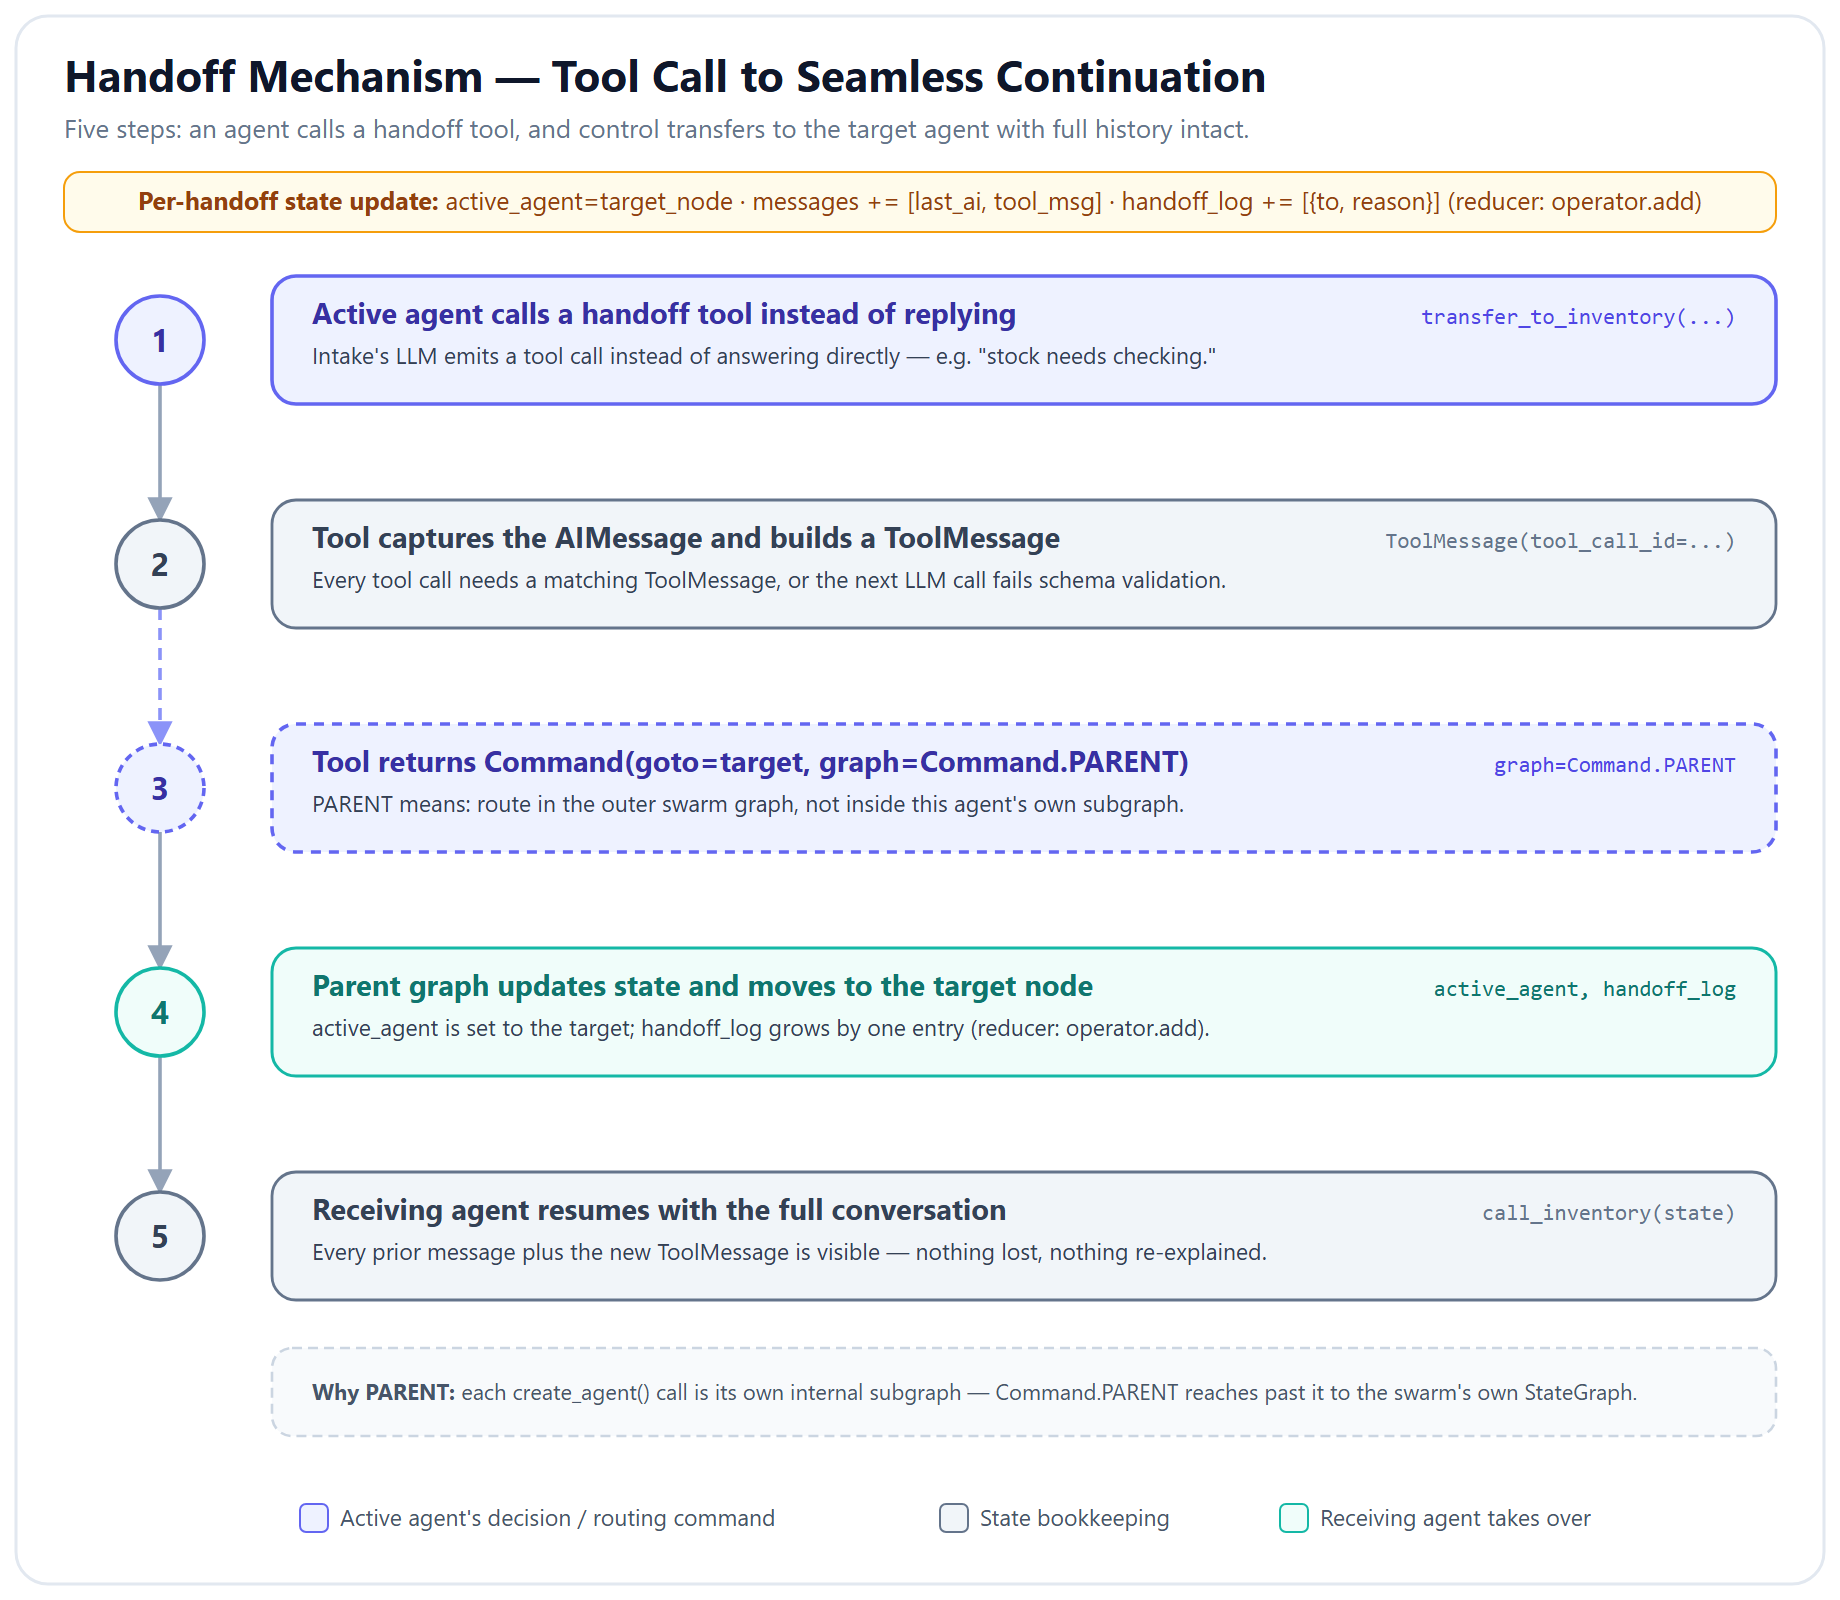

**Figure — Handoff mechanism, tool call to seamless continuation.** An agent calls a handoff tool, which captures the triggering message, returns `Command(goto=target_node, graph=Command.PARENT)`, and the receiving agent resumes with the entire conversation intact.

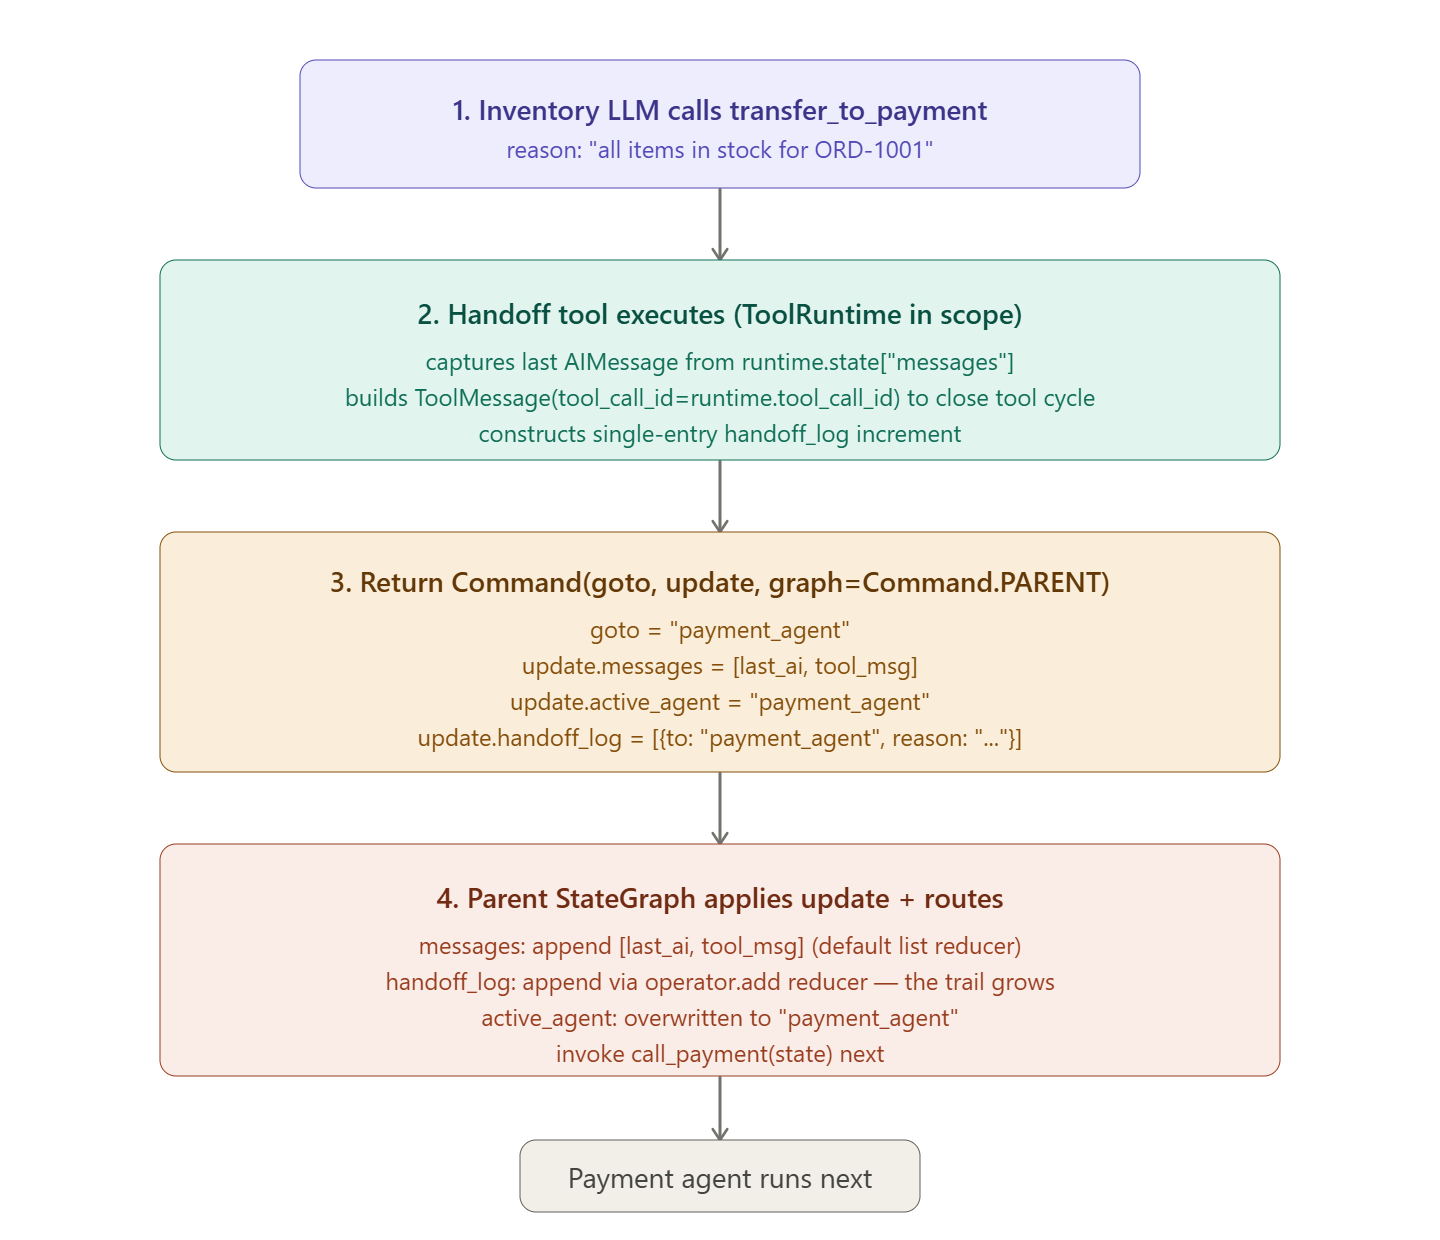

In [ ]:
# ============================================================
# Handoff Tools -- Peer-to-Peer Transfer via Command.PARENT
# ============================================================
#
# The factory function _make_handoff keeps all six handoff tools in sync --
# add a new destination and this is the only place that needs to change.

def _make_handoff(target_node: str, target_label: str):
    """Factory that builds a handoff tool for a given target agent."""
    def _handoff_to_target(reason: str, runtime: ToolRuntime) -> Command:
        """Transfer control to the target agent and record the handoff in parent state.

        Args:
            reason: Why the handoff is happening; shown to the receiving agent.
            runtime: Tool runtime, used for the current messages and the tool_call_id.

        Returns:
            A Command that routes the PARENT swarm graph to the target agent node.
        """
        # Capture the AIMessage that triggered this handoff so we can re-emit it
        # as part of the parent-state update. Without this, the parent graph
        # would see an orphaned ToolMessage and downstream agents would fail
        # schema validation on their first LLM call.
        last_ai_message = next(message for message in reversed(runtime.state["messages"])
                               if isinstance(message, AIMessage))
        handoff_tool_message = ToolMessage(
            content=f"Transferred to {target_label}: {reason}",
            tool_call_id=runtime.tool_call_id,
        )
        return Command(
            goto=target_node,
            update={
                "active_agent": target_node,
                "messages": [last_ai_message, handoff_tool_message],
                "handoff_log": [{"to": target_node, "reason": reason}],
            },
            graph=Command.PARENT,
        )
    return _handoff_to_target


@tool
def transfer_to_inventory(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off to the Inventory Agent when stock availability needs to be checked.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("inventory_agent", "Inventory Agent")(reason, runtime)


@tool
def transfer_to_payment(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off to the Payment Agent when payment processing is needed.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("payment_agent", "Payment Agent")(reason, runtime)


@tool
def transfer_to_shipping(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off to the Shipping Agent when the order is ready to be dispatched.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("shipping_agent", "Shipping Agent")(reason, runtime)


@tool
def transfer_to_returns(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off to the Returns Agent for return or refund requests.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("returns_agent", "Returns Agent")(reason, runtime)


@tool
def transfer_to_fraud(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off to the Fraud Detection Agent when suspicious activity is detected.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("fraud_agent", "Fraud Detection Agent")(reason, runtime)


@tool
def transfer_to_intake(reason: str, runtime: ToolRuntime) -> Command:
    """Hand off back to the Order Intake Agent when escalation or customer communication is needed.

    Args:
        reason: Why this handoff is needed
    """
    return _make_handoff("intake_agent", "Intake Agent")(reason, runtime)


print("6 handoff tools defined:")
for handoff_tool in [transfer_to_inventory, transfer_to_payment, transfer_to_shipping,
                     transfer_to_returns, transfer_to_fraud, transfer_to_intake]:
    print(f"  - {handoff_tool.name}")


## 5. Step 3 -- Create 6 Specialist Agents

Each agent gets:
- **Domain tools**: For performing its actual work
- **Handoff tools**: For transferring to peer agents
- **System prompt**: Defining its role and when to hand off

The tool set for each agent is deliberately scoped. An agent cannot route to a destination it has no handoff tool for — this is how we use graph *topology* to enforce workflow order, rather than relying on prompt instructions alone.

| Agent | Domain Tools | Can Hand Off To |
|-------|-------------|----------------|
| **Intake** | `check_order`, `cancel_order` | Inventory, Returns, Fraud |
| **Inventory** | `check_inventory` | Payment, Intake |
| **Payment** | `process_payment` | Shipping, Intake |
| **Shipping** | `select_carrier`, `generate_tracking` | Intake |
| **Returns** | `check_return_eligibility`, `process_refund` | Intake |
| **Fraud** | `check_fraud_risk`, `block_order` | Payment, Intake |

Note what Intake *cannot* do directly: it has no `transfer_to_payment` or `transfer_to_shipping`. Payment is only reachable through Inventory (for standard orders) or through Fraud (for low/medium risk orders that need to clear fraud first). Shipping is only reachable through Payment. This is a topology guarantee, not a prompt instruction.


In [ ]:
# ============================================================
# Create 6 Specialist Agents with create_agent
# ============================================================
# DESIGN NOTES: why each agent has the tools it has
#
# Each agent's tool set is deliberately narrow. An agent cannot route to a
# destination if it does not have the matching handoff tool. This uses the
# graph TOPOLOGY to enforce workflow order rather than relying on prompt
# instructions alone. Prompts are soft -- an LLM can misread or ignore them.
# Tool availability is hard -- an agent literally cannot call a tool it
# does not possess.
#
# Key topology choices:
# - Intake CANNOT transfer directly to Payment or Shipping. Payment is only
#   reachable through Inventory (or Fraud for low/medium risk). Shipping is
#   only reachable through Payment. This is what forces the full lifecycle
#   for a happy-path order.
# - Fraud has its own block_order tool. When risk is HIGH, fraud performs
#   the block itself before handing back to intake. This prevents intake
#   from having to invent a blocking workflow and accidentally offering the
#   customer a fabricated ID-verification process.
# - Returns has no transfer_to_payment (which would be semantically wrong --
#   refunds flow through process_refund, not back through the payment agent).
#
# Prompt discipline:
# - Each prompt has a "STRICT RULES" section listing specific fabrications
#   the agent must NOT produce (e.g., intake cannot ask for government IDs
#   or offer partial shipments).
# - Intake has an ANTI-LOOP RULE that triggers on returning-agent handoffs.
#   Without it, intake would see a message like "customer wants to finalize
#   order" still in history and restart routing after a failure -- creating
#   an infinite payment-retry loop.
# - Downstream agents use canonical handoff-reason prefixes ("payment failed:",
#   "order blocked:", "return denied:", "item out of stock:", "refund
#   processed:") so intake can reliably recognize the terminal outcome.

# --- 1. ORDER INTAKE AGENT ---
intake_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[check_order, cancel_order,
           transfer_to_inventory, transfer_to_returns, transfer_to_fraud],
    system_prompt=(
        "You are the Order Intake Agent at ShopSmart e-commerce. "
        "You are the first point of contact and the customer-facing closer.\n\n"

        "*** ANTI-LOOP RULE (read before anything else) ***\n"
        "Before routing, check the most recent ToolMessage in the conversation. "
        "If it starts with 'Transferred to Intake Agent:', another agent has just "
        "returned control to you with a result. You are now in COMMUNICATE mode, "
        "not ROUTE mode. In COMMUNICATE mode:\n"
        "  - Do NOT call transfer_to_inventory, transfer_to_payment, transfer_to_fraud, "
        "or transfer_to_returns. They caused the loop you are now trying to avoid.\n"
        "  - Your ONLY legal tool calls are cancel_order (if the customer explicitly "
        "accepts cancellation) or no tool call at all.\n"
        "  - Produce a final response to the customer summarising the outcome.\n\n"

        "ROUTING RULES (only apply when the LAST message is from the USER, not from "
        "a returning agent):\n"
        "1. Call check_order first to look up the order.\n"
        "2. If the customer is a NEW customer AND the order total is above INR 15,000, "
        "or the order contains more than 3 distinct items -> transfer_to_fraud FIRST.\n"
        "3. Otherwise, for a PENDING order -> transfer_to_inventory "
        "(inventory decides if payment can proceed).\n"
        "4. For a return/refund request -> transfer_to_returns.\n\n"

        "TERMINAL OUTCOMES (when you receive control back from another agent, "
        "communicate these plainly and END the conversation):\n"
        "  - 'Transferred to Intake Agent: payment failed ...' -> tell customer the "
        "    payment did not go through and ask if they want to cancel (call cancel_order) "
        "    or try again later (end without action).\n"
        "  - 'Transferred to Intake Agent: order blocked ...' -> tell customer the order "
        "    is blocked pending review.\n"
        "  - 'Transferred to Intake Agent: return denied ...' -> tell customer why.\n"
        "  - 'Transferred to Intake Agent: item out of stock ...' -> present options "
        "    (wait for restock OR cancel_order). If customer already accepted cancellation, "
        "    call cancel_order. Otherwise ask.\n"
        "  - 'Transferred to Intake Agent: refund processed ...' -> confirm refund ID.\n\n"

        "STRICT RULES --- VIOLATING THESE BREAKS THE SYSTEM:\n"
        "- You DO NOT have a tool to transfer directly to Payment or Shipping.\n"
        "- You CANNOT issue refunds, override return denials, or offer goodwill exceptions.\n"
        "- You CANNOT request government IDs, passport photos, selfies, OTPs, or any "
        "verification the system does not explicitly support.\n"
        "- You CANNOT offer partial shipments, item-level cancellations, or split orders.\n"
        "- Do not invent policies or workflows not backed by a tool."
    ),
)

# --- 2. INVENTORY AGENT ---
inventory_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[check_inventory, transfer_to_payment, transfer_to_intake],
    system_prompt=(
        "You are the Inventory Agent at ShopSmart e-commerce.\n\n"
        "WORKFLOW:\n"
        "1. Check stock with check_inventory for EVERY item in the order (not just the first).\n"
        "2. If ALL items are in stock -> transfer_to_payment to proceed.\n"
        "3. If ANY item is out of stock -> transfer_to_intake with reason starting "
        "'item out of stock:' followed by the specific items, stock counts, and restock dates.\n\n"
        "STRICT RULES:\n"
        "- You do not decide whether to partially ship. That is an Intake decision with the customer.\n"
        "- You do not process payments, generate tracking, or authorize refunds."
    ),
)

# --- 3. PAYMENT AGENT ---
payment_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[process_payment, transfer_to_shipping, transfer_to_intake],
    system_prompt=(
        "You are the Payment Agent at ShopSmart e-commerce.\n\n"
        "WORKFLOW:\n"
        "1. Call process_payment exactly once.\n"
        "2. On SUCCESS (response contains 'PAYMENT SUCCESS') OR 'Payment already completed' "
        "-> transfer_to_shipping.\n"
        "3. On FAILURE (response contains 'PAYMENT FAILED') -> transfer_to_intake with a "
        "reason that STARTS with the exact phrase 'payment failed:' so intake can recognize "
        "this as a terminal state. Example reason: 'payment failed: card declined for ORD-1005'.\n\n"
        "STRICT RULES:\n"
        "- Do not call process_payment more than once per handoff.\n"
        "- Do not retry payment. A failed payment goes back to intake, not back to inventory or "
        "through another loop.\n"
        "- Always include the transaction ID in your reasoning when payment succeeds."
    ),
)

# --- 4. SHIPPING AGENT ---
shipping_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[select_carrier, generate_tracking, transfer_to_intake],
    system_prompt=(
        "You are the Shipping Agent at ShopSmart e-commerce. "
        "You are the TERMINAL step for successful orders.\n\n"
        "WORKFLOW:\n"
        "1. Call select_carrier to pick the best carrier.\n"
        "2. Call generate_tracking with the chosen carrier name.\n"
        "3. Produce a FINAL response with tracking number, carrier, and ETA. "
        "This final response MUST contain NO tool calls --- it ends the conversation.\n\n"
        "STRICT RULES:\n"
        "- Do not hand off back to intake unless generate_tracking returned an error.\n"
        "- Do not offer features you cannot deliver (signature-on-delivery, delivery notifications, "
        "address changes, priority bumps). These are not supported tools."
    ),
)

# --- 5. RETURNS AGENT ---
returns_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[check_return_eligibility, process_refund, transfer_to_intake],
    system_prompt=(
        "You are the Returns Agent at ShopSmart e-commerce.\n\n"
        "WORKFLOW:\n"
        "1. Call check_return_eligibility.\n"
        "2. If ELIGIBLE -> call process_refund. Then transfer_to_intake with a reason starting "
        "'refund processed:' so intake can confirm to the customer.\n"
        "3. If DENIED -> transfer_to_intake with a reason starting 'return denied:' followed by "
        "the exact denial reason from check_return_eligibility. Your denial is FINAL.\n\n"
        "STRICT RULES:\n"
        "- There is NO goodwill-exception workflow. If the window is exceeded or an item "
        "is non-returnable, that is the final answer.\n"
        "- Do not promise manager escalation, policy overrides, or partial refunds."
    ),
)

# --- 6. FRAUD DETECTION AGENT ---
fraud_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[check_fraud_risk, block_order, transfer_to_payment, transfer_to_intake],
    system_prompt=(
        "You are the Fraud Detection Agent at ShopSmart e-commerce.\n\n"
        "WORKFLOW:\n"
        "1. Call check_fraud_risk.\n"
        "2. If risk = LOW -> transfer_to_payment to proceed.\n"
        "3. If risk = MEDIUM -> transfer_to_payment but include the flags in your reasoning.\n"
        "4. If risk = HIGH -> call block_order with the risk reason, THEN transfer_to_intake "
        "with a reason starting 'order blocked:' so intake can inform the customer.\n\n"
        "STRICT RULES:\n"
        "- HIGH risk means the order is BLOCKED. No ID-verification workflow, no OTP, "
        "no photo ID. block_order is the only disposition.\n"
        "- Do not second-guess the risk score returned by check_fraud_risk."
    ),
)

print("6 specialist agents created:")
for agent_name in ["intake_agent", "inventory_agent", "payment_agent",
                   "shipping_agent", "returns_agent", "fraud_agent"]:
    print(f"  - {agent_name}")


## 6. Step 4 -- Build the Swarm Graph

We wire the swarm as a `StateGraph` where:
- Each agent is a **node** (called via a wrapper function)
- **Handoff tools** create dynamic edges via `Command.PARENT`
- The `intake_agent` is the **entry point** (all requests start here)
- Any agent can hand off to any other agent
- The graph **ends** when an agent produces a final AI response with no tool calls

The routing logic uses `conditional_edges` to check:
1. Did the agent hand off? -> Route to `active_agent`
2. Did the agent produce a final response? -> Route to `END`

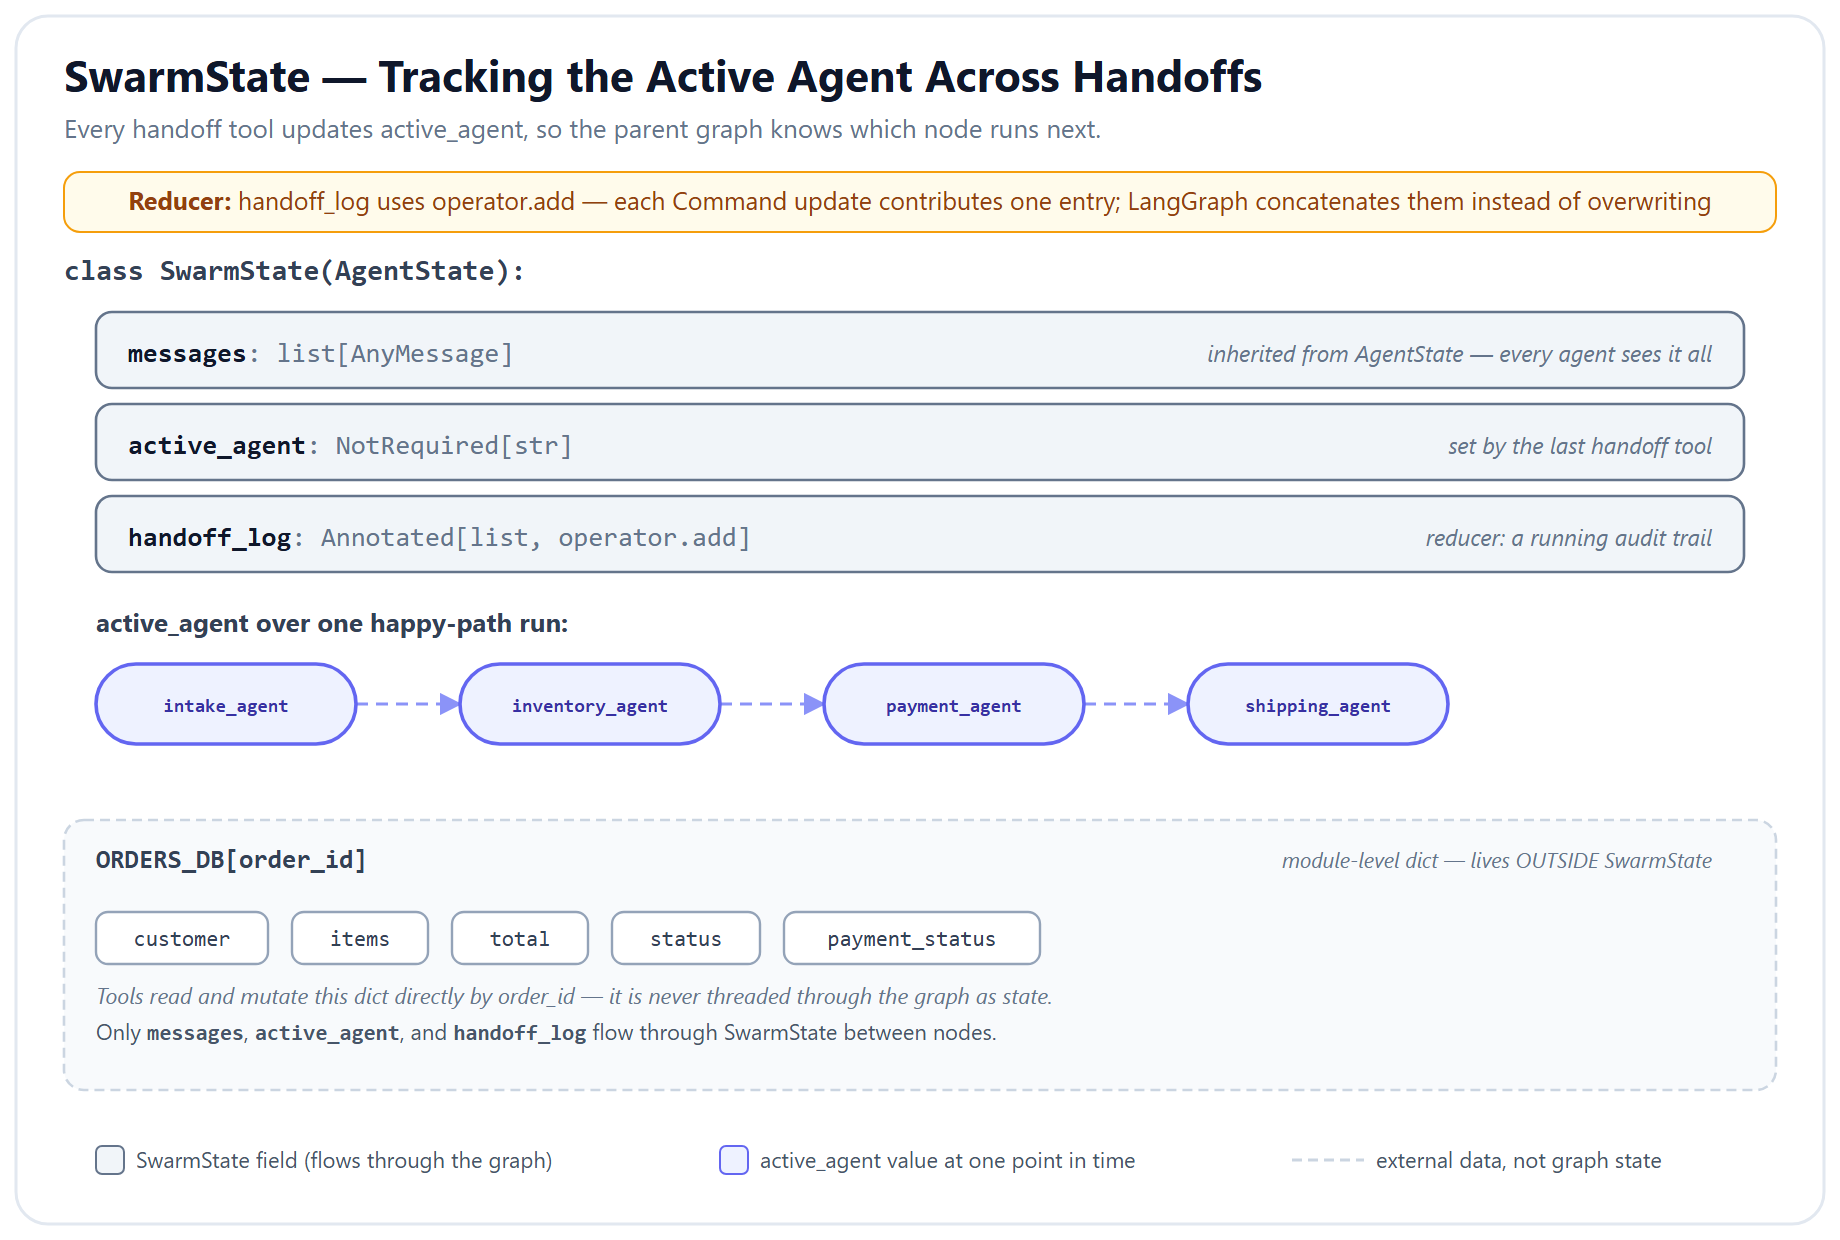

**Figure — SwarmState schema and the active_agent pointer.** `active_agent` is set by every handoff tool and read by `route_after_agent`; `handoff_log` accumulates via an `operator.add` reducer; order data lives outside graph state in a plain `ORDERS_DB` dict that tools mutate directly.

In [ ]:
# ============================================================
# Swarm State & Agent Node Wrappers
# ============================================================
# DESIGN NOTES:
#
# SwarmState extends the AgentState that create_agent expects, and adds two
# swarm-specific fields:
#
#   - active_agent: set by every handoff tool. Read by route_after_agent (next
#     cell) to decide which agent node runs next.
#
#   - handoff_log: declared with operator.add as its REDUCER. Each handoff tool
#     returns Command(update={"handoff_log": [single_entry]}, ...), and the
#     reducer concatenates these one-entry lists into a running log. Without a
#     reducer, each Command update would OVERWRITE the parent's handoff_log
#     with whatever the sub-agent could see locally -- which would be
#     incomplete, because a sub-agent's view of state does not always carry
#     fields it does not declare itself. The reducer pattern lets us build up
#     a complete audit trail without every sub-agent needing to know about
#     the trail.
#
# The call_* wrappers are thin -- they just invoke the corresponding agent
# subgraph with the current state. Each create_agent returns a compiled
# subgraph that runs its own internal LLM-call / tool-call loop until it
# either produces a final AI response (no tool calls) or invokes a handoff
# tool (which breaks out via Command.PARENT).

import operator
from typing import Annotated

class SwarmState(AgentState):
    """Swarm graph state: the shared agent conversation plus two swarm bookkeeping fields."""
    active_agent: NotRequired[str]
    handoff_log: Annotated[list, operator.add]  # reducer: concatenates entries

def call_intake(state: SwarmState):
    """Run the Order Intake Agent -- first contact, routing, and the customer-facing reply."""
    return intake_agent.invoke(state)

def call_inventory(state: SwarmState):
    """Run the Inventory Agent -- verifies warehouse stock for every item in the order."""
    return inventory_agent.invoke(state)

def call_payment(state: SwarmState):
    """Run the Payment Agent -- charges the customer exactly once, with no retry loop."""
    return payment_agent.invoke(state)

def call_shipping(state: SwarmState):
    """Run the Shipping Agent -- picks a carrier and issues the tracking number."""
    return shipping_agent.invoke(state)

def call_returns(state: SwarmState):
    """Run the Returns Agent -- checks return eligibility and issues the refund."""
    return returns_agent.invoke(state)

def call_fraud(state: SwarmState):
    """Run the Fraud Detection Agent -- scores risk and blocks HIGH-risk orders."""
    return fraud_agent.invoke(state)

print("SwarmState defined with active_agent + handoff_log (reducer: operator.add)")
print("6 agent node wrapper functions created")


In [ ]:
# ============================================================
# Build the Swarm StateGraph
# ============================================================

# Router: after each agent, check if it handed off or finished
def route_after_agent(state: SwarmState) -> Literal[
    "intake_agent", "inventory_agent", "payment_agent",
    "shipping_agent", "returns_agent", "fraud_agent", "__end__"
]:
    """Route based on active_agent, or END if agent finished without handoff."""
    messages = state.get("messages", [])

    # If the last message is an AIMessage without tool calls, the agent is done
    if messages:
        last_message = messages[-1]
        if isinstance(last_message, AIMessage) and not last_message.tool_calls:
            return "__end__"

    # Otherwise route to the active agent (set by handoff tools via Command.PARENT)
    active_agent_name = state.get("active_agent", "intake_agent")
    return active_agent_name


# All agent node names
AGENT_NODES = ["intake_agent", "inventory_agent", "payment_agent",
               "shipping_agent", "returns_agent", "fraud_agent"]

# Build the graph
builder = StateGraph(SwarmState)

# Add all 6 agents as nodes
builder.add_node("intake_agent", call_intake)
builder.add_node("inventory_agent", call_inventory)
builder.add_node("payment_agent", call_payment)
builder.add_node("shipping_agent", call_shipping)
builder.add_node("returns_agent", call_returns)
builder.add_node("fraud_agent", call_fraud)

# Entry point: all requests start at intake agent
builder.add_edge(START, "intake_agent")

# After each agent: route to the next agent OR end
all_destinations = AGENT_NODES + [END]
for agent_node_name in AGENT_NODES:
    builder.add_conditional_edges(agent_node_name, route_after_agent, all_destinations)

# Compile with memory checkpointer (for thread-based conversations)
memory = InMemorySaver()
swarm = builder.compile(checkpointer=memory)

print("Swarm graph compiled successfully!")
print(f"Nodes: {len(AGENT_NODES)} agents")
print(f"Entry: intake_agent")
print(f"Each agent can route to: {len(all_destinations)} destinations (including END)")

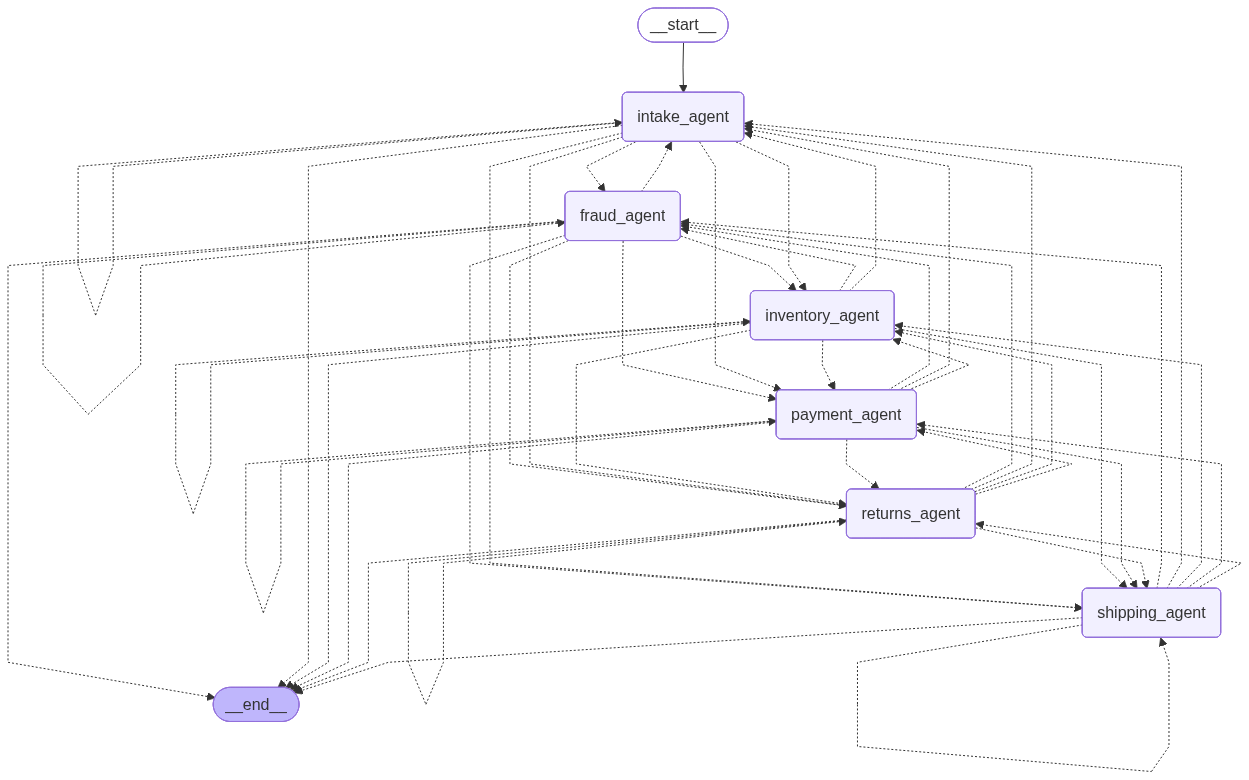

In [ ]:
# ============================================================
# Visualize the Swarm Graph
# ============================================================
try:
    graph_png_bytes = swarm.get_graph().draw_mermaid_png()
    display(Image(graph_png_bytes))
except Exception as error:
    # Fallback: print the mermaid diagram text
    print("Graph visualization (install graphviz/pyppeteer for image):")
    print(swarm.get_graph().draw_mermaid())

In [ ]:
# ============================================================
# Helper: Run a Test Case and Display Handoff Trace
# ============================================================
# DESIGN NOTES:
#
# Each test calls reset_demo_state() first so ORDERS_DB / INVENTORY_DB start
# from a clean, known baseline. Tools mutate these dicts (payment sets status,
# tracking flips to shipped, refunds mark returned), so without the reset
# a second run of the same test would see already-processed state.
#
# The handoff trace is reconstructed from state["handoff_log"] -- a structured
# list populated by the handoff tools -- not by parsing prose out of
# ToolMessage content. That keeps the observability robust to prompt tweaks.
#
# The optional expected_agents parameter lets each test assert that specific
# agents were visited. This catches the "test produces plausible output but
# skipped a required step" class of silent failure.
#
# The optional payment_overrides parameter feeds into PAYMENT_OVERRIDE so
# failure-path tests can force deterministic outcomes instead of relying on
# the 90% random success rate in process_payment.

AGENT_DISPLAY = {
    "intake_agent": "Intake",
    "inventory_agent": "Inventory",
    "payment_agent": "Payment",
    "shipping_agent": "Shipping",
    "returns_agent": "Returns",
    "fraud_agent": "Fraud",
}

def run_swarm_test(user_message, thread_id, title="", expected_agents=None,
                   payment_overrides=None):
    """Run a test through the swarm and display the conversation + handoff trace.

    Args:
        user_message: the customer's opening message
        thread_id: unique thread id for this test (isolates checkpoint history)
        title: optional header
        expected_agents: optional list of agent names that MUST appear in the trace
                         (e.g., ["intake_agent","inventory_agent"]); prints a soft
                         assertion line at the end of the run
        payment_overrides: optional {order_id: "fail"|"succeed"} dict applied before run
    """
    if title:
        print(f"{'='*70}")
        print(f"  {title}")
        print(f"{'='*70}")

    # Deterministic starting state for every test
    reset_demo_state()
    if payment_overrides:
        PAYMENT_OVERRIDE.update(payment_overrides)

    print(f"\nUser: {user_message}\n")

    result = swarm.invoke(
        {"messages": [{"role": "user", "content": user_message}],
         "handoff_log": []},
        config={"configurable": {"thread_id": thread_id}, "recursion_limit": 50},
    )

    # Reconstruct trace from structured handoff_log (not string-parsing)
    handoff_log = result.get("handoff_log", []) or []
    trace = ["intake_agent"] + [handoff_entry["to"] for handoff_entry in handoff_log]

    print("HANDOFF TRACE:")
    display_trace = [AGENT_DISPLAY.get(agent_name, agent_name) for agent_name in trace]
    print("  " + " --> ".join(display_trace))

    if handoff_log:
        print("\nHANDOFF REASONS:")
        for position, handoff_entry in enumerate(handoff_log, 1):
            print(f"  {position}. -> "
                  f"{AGENT_DISPLAY.get(handoff_entry['to'], handoff_entry['to'])}: "
                  f"{handoff_entry['reason'][:100]}")
    print()

    # Final AI response
    for message in reversed(result["messages"]):
        if isinstance(message, AIMessage) and message.content and not message.tool_calls:
            print(f"FINAL RESPONSE (from {AGENT_DISPLAY.get(trace[-1], trace[-1])}):")
            print(f"  {message.content[:700]}")
            break

    # Soft assertion on expected trace
    if expected_agents:
        missing_agents = [agent_name for agent_name in expected_agents
                          if agent_name not in trace]
        print()
        if missing_agents:
            print(f"  EXPECTED CHECK: FAIL --- trace missing required agents: {missing_agents}")
        else:
            print(f"  EXPECTED CHECK: PASS --- all required agents visited ({expected_agents})")

    print()
    return result, trace


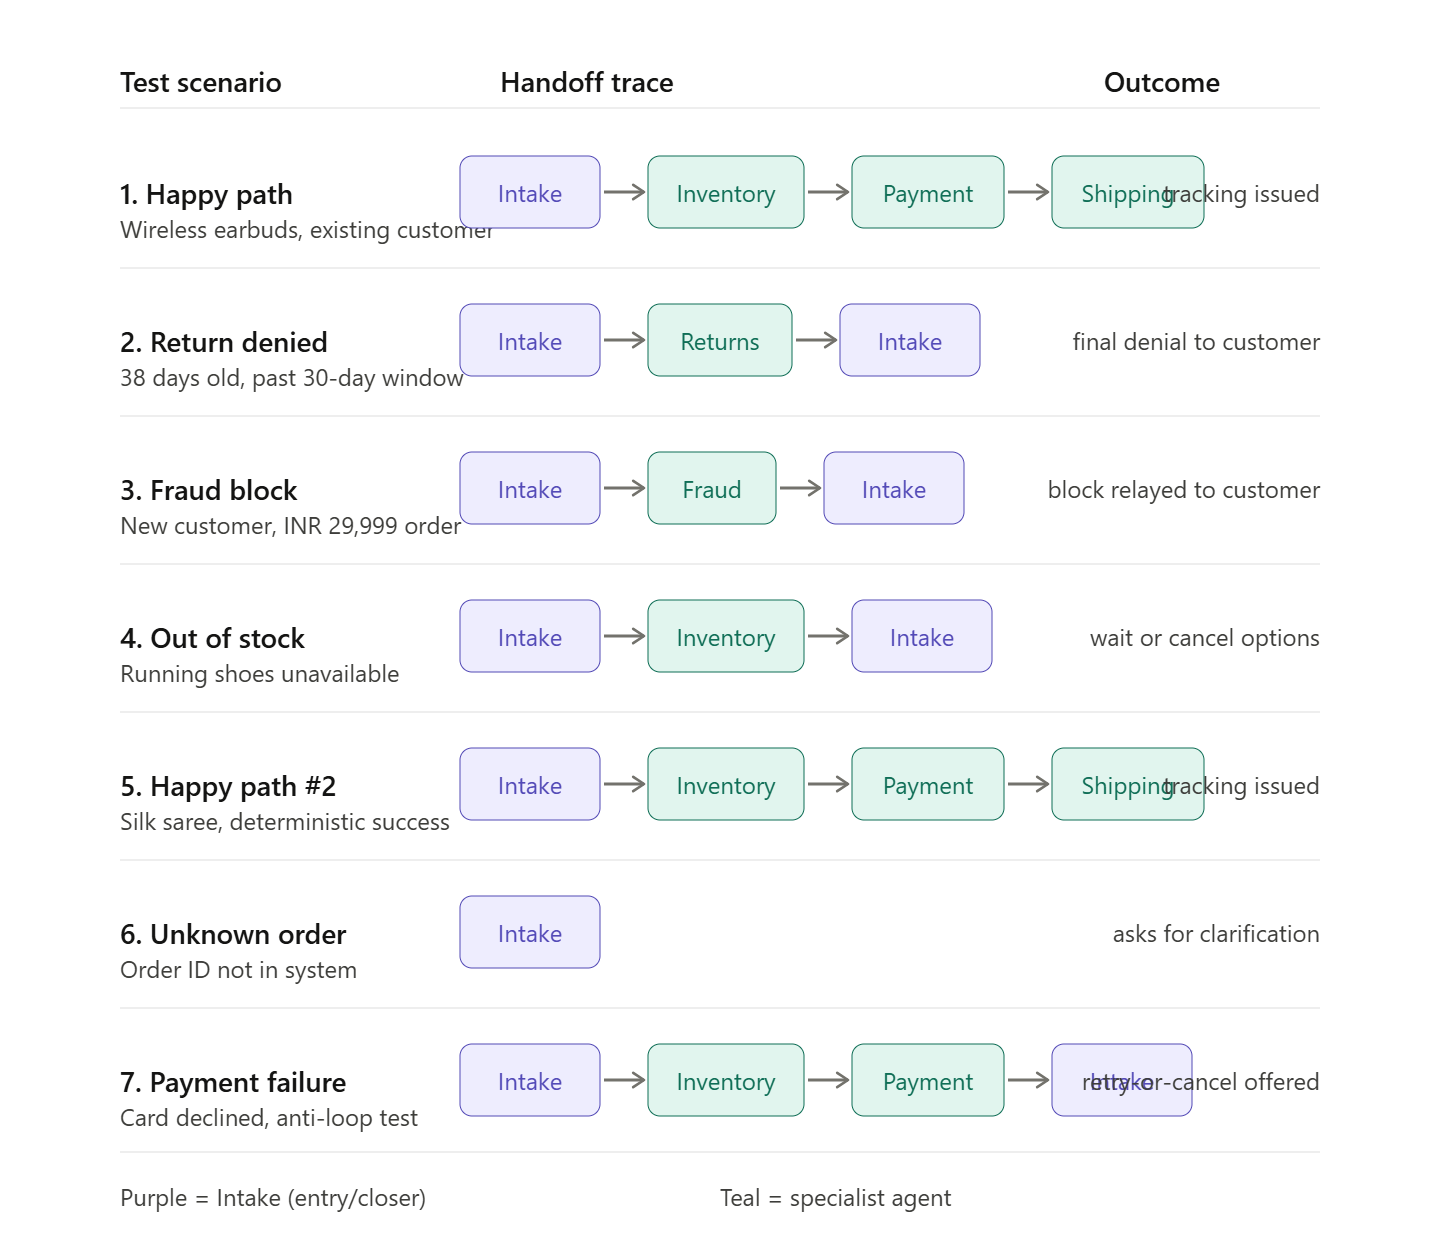

## 7. Test Case 1 -- New Order (Happy Path)

**Scenario:** Customer Ananya Sharma wants to place order ORD-1001 for Wireless Earbuds.

**Expected handoff flow:**
```
Intake Agent --> Inventory Agent --> Payment Agent --> Shipping Agent
```

This tests the full happy-path lifecycle: validate order, check stock, process payment, and dispatch.

In [ ]:
# ============================================================
# Test Case 1: New Order -- Full Happy Path
# ============================================================
# Expected flow: Intake -> Inventory -> Payment -> Shipping
# This verifies the full lifecycle for a standard pending order from an
# existing customer. Intake cannot skip Inventory (it has no transfer_to_payment
# tool), so this is an end-to-end integration test of the topology constraint.

result_1, trace_1 = run_swarm_test(
    user_message=(
        "I want to place order ORD-1001 for Wireless Earbuds. "
        "My name is Ananya Sharma from Mumbai."
    ),
    thread_id="test-happy-path",
    title="TEST CASE 1: New Order (Happy Path -- Full Lifecycle)",
    expected_agents=["intake_agent", "inventory_agent", "payment_agent", "shipping_agent"],
    payment_overrides={"ORD-1001": "succeed"},  # deterministic: avoid 10% RNG failure
)


## 8. Test Case 2 -- Return Request (Past Return Window)

**Scenario:** Customer Vikram Singh wants to return order ORD-1004 (Laptop Stand + USB-C Hub, delivered March 1). Today is April 8, which is **38 days** after delivery — past the 30-day return window.

**Expected handoff flow:**
```
Intake Agent --> Returns Agent --> Intake Agent (final denial to customer)
```

This tests the return eligibility check and the **denial** path. The Returns agent's denial is FINAL — Intake must communicate it plainly without fabricating goodwill-exception workflows, manager escalations, or policy overrides.


In [ ]:
# ============================================================
# Test Case 2: Return Request (past 30-day window)
# ============================================================
# Expected flow: Intake -> Returns -> Intake
# ORD-1004 was delivered on 2026-03-01; today is 2026-04-08 (38 days ago).
# The return window is 30 days, so Returns should issue a FINAL denial.
# Intake must relay the denial plainly -- no fabricated goodwill-exception
# workflows, no manager-escalation promises.

result_2, trace_2 = run_swarm_test(
    user_message=(
        "I want to return my order ORD-1004. The Laptop Stand and USB-C Hub "
        "are not what I expected. My name is Vikram Singh."
    ),
    thread_id="test-return",
    title="TEST CASE 2: Return Request (past 30-day window)",
    expected_agents=["intake_agent", "returns_agent"],
)


## 9. Test Case 3 -- Suspicious Order (Fraud Detection)

**Scenario:** New customer Rohan Das places order ORD-1010 for Premium Headphones worth INR 29,999.

**Expected handoff flow:**
```
Intake Agent --> Fraud Agent --> Intake Agent (block relayed to customer)
```

This triggers the `high_value_new_customer` fraud rule: new customer placing an order above the INR 15,000 threshold. The Fraud agent classifies this as HIGH risk, calls `block_order` itself, and hands back to Intake. Intake must relay the block plainly — NOT offer ID verification, OTP, or photo ID workflows that the system does not support.


In [ ]:
# ============================================================
# Test Case 3: Suspicious Order -- Fraud Detection (HIGH risk -> Block)
# ============================================================
# Expected flow: Intake -> Fraud -> Intake
# ORD-1010 is a new customer (Rohan Das) placing a INR 29,999 order, which
# exceeds the INR 15,000 new-customer threshold. Fraud should classify as
# HIGH, call block_order itself, and hand back to Intake with a canonical
# "order blocked:" reason. Intake must relay the block -- NOT offer to
# verify the customer with government ID, OTP, or photo ID (those workflows
# don't exist in the system).

result_3, trace_3 = run_swarm_test(
    user_message=(
        "I am a new customer Rohan Das and I want to place order ORD-1010 "
        "for Premium Headphones worth INR 29,999."
    ),
    thread_id="test-fraud",
    title="TEST CASE 3: Suspicious Order (Fraud HIGH -> Block)",
    expected_agents=["intake_agent", "fraud_agent"],
)


## 10. Test Case 4 -- Out of Stock Item

**Scenario:** Customer Rahul Verma wants to check order ORD-1002 which includes Running Shoes (OUT OF STOCK) and a Sports Watch.

**Expected handoff flow:**
```
Intake Agent --> Inventory Agent --> (Back to Intake -- out of stock notification)
```

This tests the out-of-stock handling path where the inventory agent sends the customer back to intake with restock information.

In [ ]:
# ============================================================
# Test Case 4: Out of Stock Item
# ============================================================
# Expected flow: Intake -> Inventory -> Intake
# ORD-1002 contains Running Shoes (stock: 0, restock 2026-04-15) and a Sports
# Watch (in stock). Inventory should detect the OOS item and hand back to
# Intake with "item out of stock:" reason. Intake must offer the REAL options
# the system supports (wait for restock OR cancel_order the whole order) --
# NOT fabricated partial shipments or per-item cancellations.

result_4, trace_4 = run_swarm_test(
    user_message=(
        "Hi, I placed order ORD-1002 for Running Shoes and a Sports Watch. "
        "Can you check if everything is in stock and ready to ship? "
        "I am Rahul Verma."
    ),
    thread_id="test-out-of-stock",
    title="TEST CASE 4: Out of Stock Item",
    expected_agents=["intake_agent", "inventory_agent"],
)


## 11. Test Case 5 -- Happy Path #2 (Silk Saree)

**Scenario:** Existing customer Meera Joshi wants to finalize order ORD-1005 for a Silk Saree (INR 15,999, in stock in Kolkata).

A second happy-path test, complementing Test 1. Uses a different order, a different customer, a different city, and a different price point (right at the fraud threshold but customer is NOT new, so fraud does not trigger). Also uses `payment_overrides={"ORD-1005": "succeed"}` to force deterministic payment success — otherwise the 10% random failure rate in `process_payment` would occasionally cause this test to land on the failure branch.


In [ ]:
# ============================================================
# Test Case 5: Happy Path #2 -- Silk Saree (full lifecycle)
# ============================================================
# Expected flow: Intake -> Inventory -> Payment -> Shipping
# Same shape as Test 1 but exercises a different code path: different order,
# different customer, different warehouse, different price point. Forces
# deterministic payment success so the test reliably reaches Shipping.

result_5, trace_5 = run_swarm_test(
    user_message=(
        "I am Meera Joshi and I want to complete order ORD-1005 for a Silk Saree. "
        "Please confirm stock and ship it to Kolkata."
    ),
    thread_id="test-happy-path-2",
    title="TEST CASE 5: Full Happy Path (Saree)",
    expected_agents=["intake_agent", "inventory_agent", "payment_agent", "shipping_agent"],
    payment_overrides={"ORD-1005": "succeed"},  # deterministic: avoid 10% RNG failure
)


## 12. Test Case 6 -- Unknown Order ID (Graceful Failure)

**Scenario:** Customer asks about an order ID that does not exist in the system.

This exercises the error path where `check_order` returns "not found". The intake agent must recognise the response and respond plainly — not guess, not fabricate an order, not offer to create one.


In [ ]:
# ============================================================
# Test Case 6: Unknown Order ID (graceful failure)
# ============================================================
# Expected flow: Intake only
# The customer asks about a non-existent order. check_order returns a
# "not found" response. Intake should recognize this and respond plainly --
# no guessing, no fabricated order details, no offer to create one.

result_6, trace_6 = run_swarm_test(
    user_message="Hi, can you check order ORD-9999 for me? I think I placed it last week.",
    thread_id="test-unknown-order",
    title="TEST CASE 6: Unknown Order ID",
    expected_agents=["intake_agent"],
)


## 13. Test Case 7 -- Forced Payment Failure

**Scenario:** Customer Meera Joshi tries to finalize ORD-1005, but we deterministically force the payment to fail using `payment_overrides={"ORD-1005": "fail"}`.

This tests the failure path end-to-end. Critically, it verifies the intake agent's anti-loop rule: when Payment hands back with a "payment failed:" reason, Intake must recognize this as a terminal state and communicate it to the customer — NOT restart routing by calling `transfer_to_inventory` again, which would create an infinite retry loop.


In [ ]:
# ============================================================
# Test Case 7: Forced Payment Failure
# ============================================================
# Expected flow: Intake -> Inventory -> Payment -> Intake (final response)
# Uses PAYMENT_OVERRIDE to deterministically fail the payment call. This is
# the key test for the anti-loop rule: Intake must recognize "payment failed:"
# as a terminal handoff and stop routing, instead of re-running its routing
# logic on the original user message (which would send the order back through
# Inventory -> Payment -> fail -> ... forever).

result_7, trace_7 = run_swarm_test(
    user_message=(
        "I want to finalize order ORD-1005 for the Silk Saree please. I am Meera Joshi."
    ),
    thread_id="test-payment-fail",
    title="TEST CASE 7: Payment Failure Path",
    expected_agents=["intake_agent", "inventory_agent", "payment_agent"],
    payment_overrides={"ORD-1005": "fail"},
)


## 14. Handoff Trace Analysis

Let us visualize how agents handed off to each other across all seven test cases. This is the key observable artifact of the Swarm pattern — agents self-organizing without any central supervisor directing traffic. Each test case follows a different path through the swarm, determined entirely by the agents themselves.

The trace is read from a structured `handoff_log` field in state (populated by every handoff tool via the `operator.add` reducer), so the analysis does not depend on string-parsing message content.


In [ ]:
# ============================================================
# Handoff Trace Summary Across All Test Cases
# ============================================================

test_cases = [
    ("Test 1: Full Happy Path", trace_1),
    ("Test 2: Return Denied (past window)", trace_2),
    ("Test 3: Fraud HIGH -> Block", trace_3),
    ("Test 4: Out of Stock", trace_4),
    ("Test 5: Happy Path #2 (Meera/Silk Saree)", trace_5),
    ("Test 6: Unknown Order ID", trace_6),
    ("Test 7: Forced Payment Failure", trace_7),
]

print("=" * 70)
print("  SWARM HANDOFF TRACE SUMMARY")
print("=" * 70)

for test_name, trace in test_cases:
    display_trace = [AGENT_DISPLAY.get(agent_name, agent_name) for agent_name in trace]
    print(f"\n{test_name}")
    print(f"  Agents involved: {len(set(trace))}  (unique)")
    print(f"  Total hops:      {len(trace)}")
    print(f"  Flow: {' --> '.join(display_trace)}")

print(f"\n{'='*70}")
all_traces = [trace for _, trace in test_cases]
total_hops = sum(len(trace) for trace in all_traces)
total_handoffs = sum(len(trace) - 1 for trace in all_traces)
print(f"Total agent visits across all tests: {total_hops}")
print(f"Total handoffs: {total_handoffs}")

from collections import Counter
all_visits = Counter()
for trace in all_traces:
    for agent_name in trace:
        all_visits[agent_name] += 1

print(f"\nAgent activity (visits across all tests):")
for agent_name, visit_count in all_visits.most_common():
    activity_bar = "#" * visit_count
    print(f"  {AGENT_DISPLAY.get(agent_name, agent_name):12s}: {visit_count} visits {activity_bar}")

# Coverage check: did every agent get exercised at least once?
missing_agents = [agent_name for agent_name in AGENT_DISPLAY
                  if all_visits.get(agent_name, 0) == 0]
print(f"\nAgent coverage: {len(AGENT_DISPLAY) - len(missing_agents)}/{len(AGENT_DISPLAY)}")
if missing_agents:
    print(f"  Never visited: {missing_agents}")
else:
    print(f"  All 6 agents exercised at least once.")


## 15. The Prebuilt Shortcut — `create_swarm`

Everything you just hand-built is exactly what the **`langgraph-swarm`** package packages up. Now that
the mechanics are visible, here is the same system in a fraction of the code.

| What you hand-built | What `langgraph-swarm` provides |
|---|---|
| `SwarmState` with an `active_agent` field | `SwarmState` (the default `state_schema`) |
| Six `transfer_to_*` tools returning `Command(goto=..., graph=Command.PARENT)` | `create_handoff_tool(agent_name=...)` — auto-names the tool `transfer_to_<agent_name>` |
| `route_after_agent` + `add_conditional_edges` on every agent | `add_active_agent_router()`, wired for you by `create_swarm` |
| Six `call_*` node wrappers + `builder.add_node(...)` | pass the compiled agents straight to `create_swarm(agents=[...])` |
| Choosing the entry point | `default_active_agent="intake_agent"` |

**The verified API:**

```python
create_swarm(
    agents: list[Pregel],              # compiled agents — each MUST have a name=
    *,
    default_active_agent: str,         # who handles the first message
    state_schema: StateSchemaType = SwarmState,
    context_schema: type[Any] | None = None,
) -> StateGraph                        # still needs .compile(checkpointer=...)

create_handoff_tool(
    *,
    agent_name: str,                   # target NODE name, snake_case
    name: str | None = None,           # defaults to f"transfer_to_{agent_name}"
    description: str | None = None,    # defaults to f"Ask agent {agent_name} for help"
) -> BaseTool
```

> **Why we still built it by hand first.** The prebuilt route hides the two ideas this lab exists to
> teach — that a handoff is *just a tool returning a `Command`*, and that `active_agent` in state is
> what makes the next hop deterministic. Reach for `create_swarm` in production once you can picture
> what it generates; reach for the hand-built form when you need a custom state field (our
> `handoff_log` audit trail is a good example — it is not part of the default `SwarmState`).

In [ ]:
# ============================================================
# The same swarm, built with langgraph-swarm
# ============================================================
# Requires: langgraph-swarm (already in the setup cell at the top of this notebook).
#
# Two differences from the hand-built version:
#   1. Each agent needs an explicit `name=` — create_swarm routes by agent name.
#   2. Handoff tools come from create_handoff_tool() instead of being written by hand. The generated
#      tool is named transfer_to_<agent_name>, which is exactly our own naming convention.
from langgraph_swarm import create_swarm, create_handoff_tool

# Intake can reach Inventory, Returns and Fraud — the SAME deliberately narrow topology as before.
# (Topology is still enforced by which handoff tools an agent holds, not by prompt wording.)
prebuilt_intake_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[
        lookup_order,
        create_handoff_tool(agent_name="inventory_agent"),
        create_handoff_tool(agent_name="returns_agent"),
        create_handoff_tool(agent_name="fraud_agent"),
    ],
    system_prompt="You are the intake agent for ShopSmart order processing.",
    name="intake_agent",          # REQUIRED — create_swarm routes by this name
)

prebuilt_inventory_agent = create_agent(
    model="openai:gpt-5-mini",
    tools=[
        check_inventory,
        create_handoff_tool(agent_name="payment_agent"),
        create_handoff_tool(agent_name="intake_agent"),
    ],
    system_prompt="You are the inventory agent. Confirm stock, then hand off to payment.",
    name="inventory_agent",
)

# ... the remaining four specialists (payment, shipping, returns, fraud) follow the identical shape.

prebuilt_swarm = create_swarm(
    agents=[prebuilt_intake_agent, prebuilt_inventory_agent],   # add the other four here
    default_active_agent="intake_agent",
).compile(checkpointer=memory)                                   # same checkpointer as before

print("Prebuilt swarm compiled.")
print("  agents        :", [node for node in prebuilt_swarm.get_graph().nodes if node not in ("__start__", "__end__")])
print("  entry point   : intake_agent")
print("\nCompare with the hand-built `swarm` above: same behaviour, ~80% less wiring code,")
print("but the handoff mechanics are now hidden inside the library.")

## 16. When to Use Which Multi-Agent Pattern

Now that we have built both a Supervisor (Lab 3.1) and a Swarm (Lab 3.3), here is a practical decision guide:

| Scenario | Best Pattern | Why |
|----------|-------------|-----|
| Customer support with clear categories | **Supervisor** | Well-defined routing rules, consistent SLA |
| E-commerce order lifecycle (this lab) | **Swarm** | Organic workflow, agents know their next step |
| Independent parallel research tasks | **Subagents** | Isolated execution, no shared state needed |
| Multi-step form wizard with state | **Handoffs (single agent)** | One agent, dynamic configuration via middleware |
| Simple FAQ routing | **Skills** | Minimal overhead, prompt-only switching |

### Key Architectural Decision: Swarm vs Supervisor

| Question | If YES -> Swarm | If YES -> Supervisor |
|----------|----------------|---------------------|
| Do agents know their logical next step? | Agents decide autonomously | Supervisor decides for them |
| Is the workflow linear/sequential? | Agents chain naturally | Supervisor tracks progress |
| Do you need consistent routing guarantees? | Not critical | Supervisor provides consistency |
| Are there many possible paths through the system? | Swarm handles organically | Supervisor needs exhaustive rules |
| Do you need audit/compliance logging? | Harder (distributed) | Easier (central control point) |

### Code Comparison

```python
# SUPERVISOR (Lab 3.1): a custom StateGraph node classifies; conditional edges route
def supervisor_router(state: CustomerSupportState) -> dict:
    """Classify the ticket and write the routing decision into state."""
    ...   # structured-output LLM call + escalation business rules

builder.add_conditional_edges("supervisor", route_ticket, {
    "quick_answer": "quick_answer",       "order_handler": "order_handler",
    "returns_handler": "returns_handler", "billing_handler": "billing_handler",
    "product_handler": "product_handler", "escalation": "escalation",
})
# EVERY ticket passes through the supervisor first -- it alone decides who handles it.
# Note it is NOT a create_agent: the supervisor is a plain node, so routing stays deterministic.

# SWARM (Lab 3.3): Agents hand off to each other directly
intake = create_agent(tools=[check_order, transfer_to_inventory, transfer_to_fraud, ...])
inventory = create_agent(tools=[check_inventory, transfer_to_payment, ...])
# Each agent decides its own next step -- no central coordinator needed
```

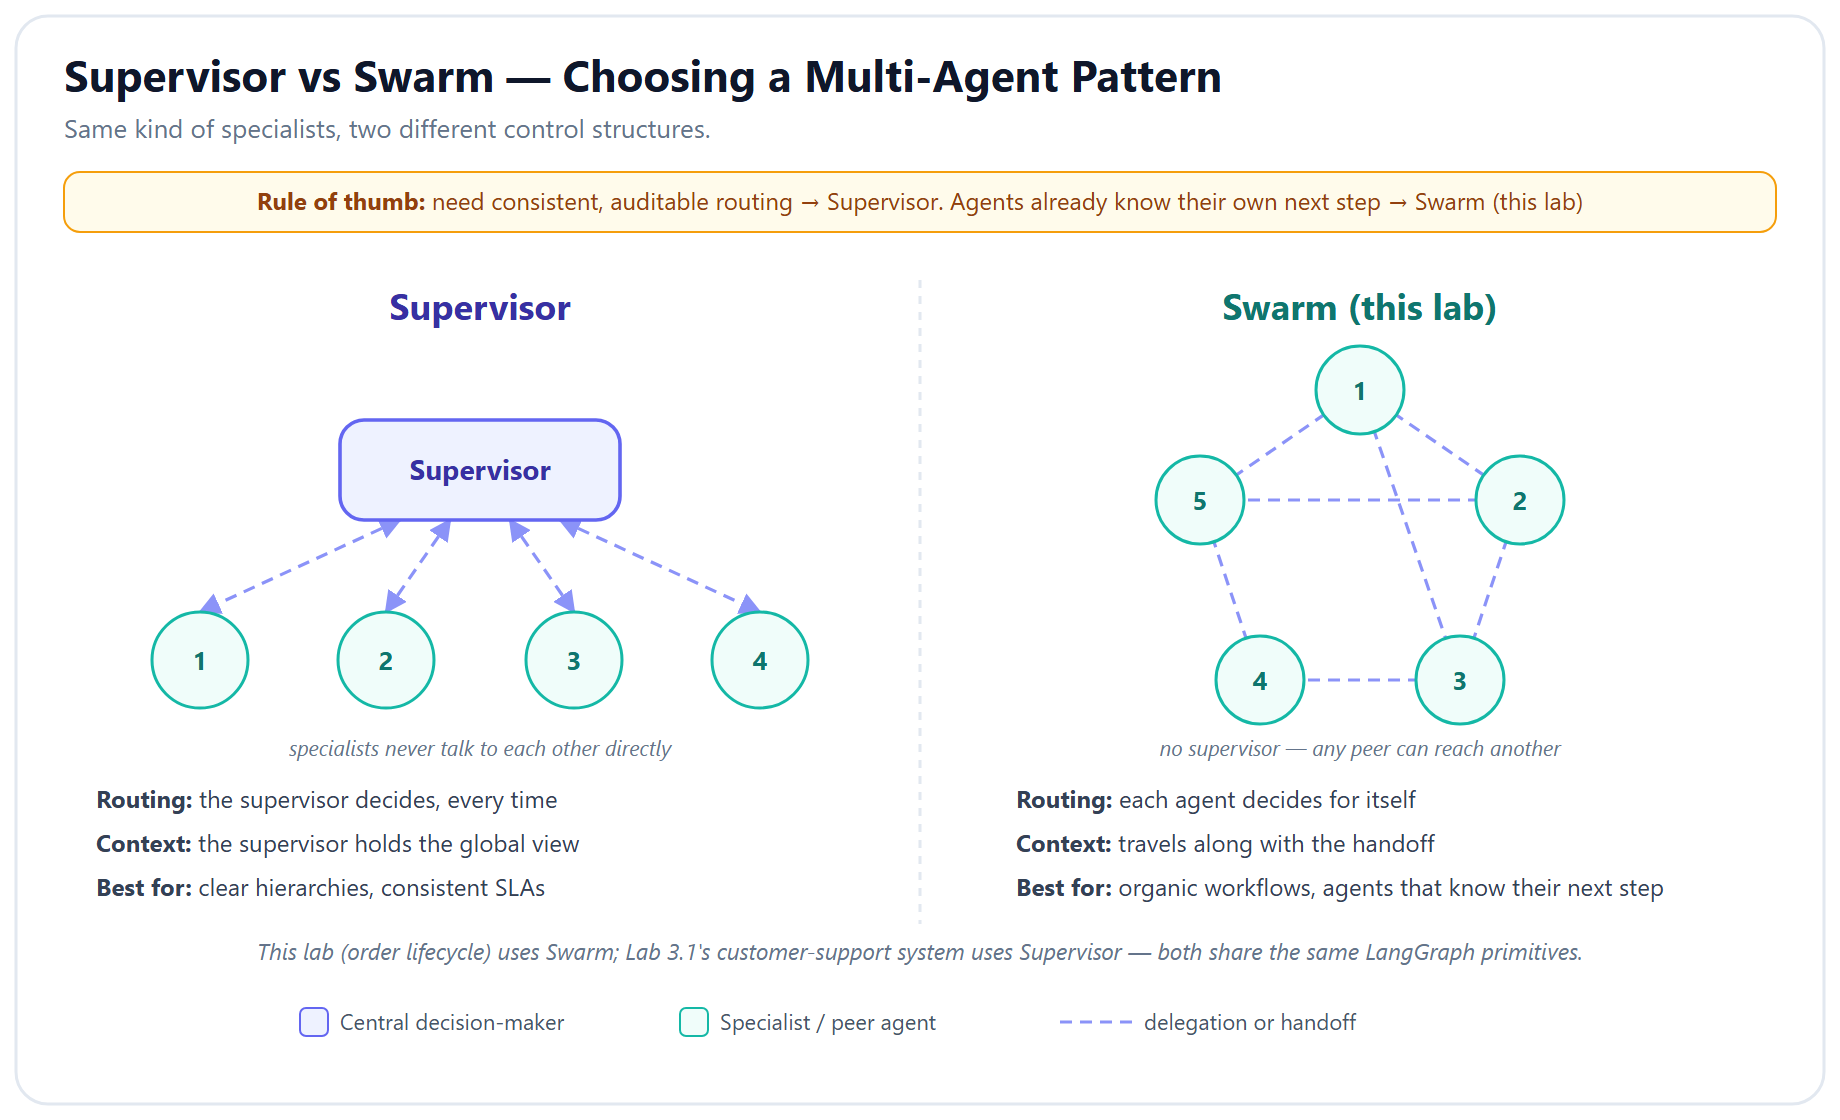

**Figure — Supervisor vs Swarm, choosing a multi-agent pattern.** A central supervisor delegates and specialists report back (star), versus peer agents handing off directly with context traveling along (mesh) — pick based on how much routing consistency the workflow needs.

## 17. Conclusion and Key Takeaways

### What We Built

| Topic | What We Built |
|-------|--------------|
| Swarm Pattern | 6 autonomous agents with peer-to-peer handoffs |
| Handoff Tools | `Command(goto=..., graph=Command.PARENT)` + structured `handoff_log` with an `operator.add` reducer |
| Agent Creation | `create_agent` with tightly-scoped domain tools + handoff tools |
| StateGraph | Decentralized graph with conditional routing after each agent |
| Workflow Enforcement | Topology-enforced order (intake cannot skip inventory; fraud owns its block) |
| Test Suite | 7 scenarios covering happy path, returns, fraud, OOS, unknown ID, payment failure, alternate happy path |
| Reproducibility | `reset_demo_state()` between tests + `PAYMENT_OVERRIDE` for deterministic failures |

### Key Takeaways

1. **Swarm = Peer-to-peer handoffs with NO central supervisor** — each agent autonomously decides to handle or hand off.
2. **Topology beats prompting** for enforcing workflow order. Removing `transfer_to_payment` from the intake agent's toolset is a harder guarantee than writing "always check inventory first" in a prompt.
3. **Every denial path needs a real tool.** `cancel_order` and `block_order` give agents honest fulfillment paths for scenarios where they would otherwise have to fabricate one.
4. **Structured state beats string parsing.** Reading `handoff_log` directly from state is how production observability works — the pattern scales from here.
5. **The anti-loop rule matters.** When an agent returns control to the intake agent with a terminal result, intake must be in "communicate" mode, not "route" mode. Without this, the original user message still in context tempts the model to restart routing and creates retry loops.
6. **`ToolRuntime`** provides `tool_call_id` and `state` access needed for valid conversation history during handoffs.
7. **Swarm is best for organic workflows** where agents naturally know their logical next step; Supervisor (Lab 3.1) is best for controlled routing where you need consistent, auditable decisions.

### Known Limitations

Tightening tool sets and prompts removes most of the obvious failure modes, but some issues are inherent to LLM-based agents and worth acknowledging:

- **Prompts are soft constraints.** Even with explicit "DO NOT" rules in every system prompt, the model can still drift under sufficiently unusual phrasing. The topology fixes (scoped tool sets, `cancel_order` and `block_order` as real tools) are the *hard* constraints — the prompt rules are belt-and-braces.
- **The intake agent is still a traffic concentrator.** Most test flows start and end at intake. A true peer-to-peer swarm with more autonomy would let downstream agents respond directly to the customer. That is an architectural extension worth exploring.
- **State mutation is not concurrency-safe.** `ORDERS_DB` is a dict; two concurrent requests for the same order could race. Production would use a transactional store.
- **The fraud signal is rule-based, not learned.** A real fraud model would use historical patterns, device fingerprinting, and behavioral signals — this lab demonstrates the *routing* pattern, not fraud ML.
- **No real HITL.** When fraud blocks an order, we mark it blocked — we do not route to a human for adjudication. Adding `interrupt()` at the block point is a natural next step (see Lab 3.2 for the HITL pattern).

### Extensions to Try

1. Add a **human-in-the-loop** approval step for HIGH-risk blocked orders using `interrupt()`.
2. Add a **priority queue** — high-value orders route to a premium shipping carrier.
3. Build a **dashboard** that visualizes handoff patterns in real-time using LangGraph streaming.
4. Replace `ORDERS_DB` and `INVENTORY_DB` with **SQLite-backed repositories** so multiple concurrent runs are safe.
5. Add a **Customer Service Agent** that handles general inquiries before routing to intake.
6. Introduce **structured audit logging** — every tool call, every handoff, every decision, with timestamps.

Each of these is a weekend-scale extension and each one measurably strengthens the project.
